# Hallucination monitors: every number behind the literature review

EE 456 honors option, Penn State, Fall 2026. This notebook holds every calculation the literature review cites, in the order the review makes its argument. Each phase says what it computes, which paper it mirrors, and why it matters. All figures are also written to `results/figs/`.

| Phase | Question | Paper it mirrors | Lit-review section |
|---|---|---|---|
| 1 | Does the model's own output probability know when it is wrong? | Orgad et al. 2024 (output-based baselines), Kadavath et al. 2022 (calibration) | 1. Hallucination as uncertainty |
| 2 | Does sampling disagreement (semantic entropy) know? | Farquhar et al., *Nature* 2024 | 1. Hallucination as uncertainty |
| 3 | How large is the confident-and-wrong population that both miss? | Simhi et al. 2025 (CHOKE) | 2. The blind spot |
| 4 | Does the residual stream know? (probes) | Orgad et al. 2024, Marks & Tegmark 2023 | 3. Internal signal |
| 5 | Side-by-side with the papers; stratified axis cosine | CSO-LLM (Miller et al.) | 4. Synthesis |

**Setup shared by every phase.** Qwen3-0.6B and Qwen3-4B, thinking off, closed-book TriviaQA validation (first 2,000 questions), 4-shot terse prompt, greedy decoding. "Correct" means a gold alias appears in the answer after normalization (`contains_match`). "Confident" means the first content token of the answer had probability at least 0.8. Pipeline: `src/pilot/run_pilot.py`. These are not exact replications of any paper: different models, one dataset, lexical labels. Where a paper's number is quoted, it is for orientation, not comparison.

In [1]:
import json, sys, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src" / "pilot"))
FIG_DIR = ROOT / "results" / "figs"; FIG_DIR.mkdir(parents=True, exist_ok=True)

# colophon palette
INK, MUTED, RULE, PAPER, CARD = "#26251f", "#6f6f69", "#c9c6bd", "#eeece6", "#e6e3dc"
ACCENT, ACCENT_TEXT = "#bd6593", "#b43c7a"
C_CORRECT, C_WRONG = INK, ACCENT
MODEL_COLORS = {"Qwen3-0.6B": "#4a7c8c", "Qwen3-4B": INK}
SCORE_COLORS = {"first_tok_prob": ACCENT, "top2_gap": "#4a7c8c", "seq_logprob": "#b08a3c", "min_tok_prob": MUTED}
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": RULE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})
THRESHOLD = 0.8
RUNS = {"Qwen3-0.6B": "pilot_qwen3_0.6b", "Qwen3-4B": "pilot_qwen3_4b"}

def load_records(run):
    df = pd.read_json(ROOT / "results" / run / "records.jsonl", lines=True)
    df["correct"] = df["contains_match"].astype(int)
    df["confident"] = df["first_tok_prob"] >= THRESHOLD
    return df

REC = {m: load_records(r) for m, r in RUNS.items()}

def auroc(y, s):
    y = np.asarray(y); s = np.asarray(s)
    return float(roc_auc_score(y, s)) if len(np.unique(y)) == 2 else float("nan")

def boot_ci(y, s, n=1000, seed=0):
    rng = np.random.default_rng(seed); y = np.asarray(y); s = np.asarray(s); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2: vals.append(roc_auc_score(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight"); plt.show()

def label_bars(ax, bars, fmt="{:.2f}", dy=0.005, **kw):
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, h + dy, fmt.format(h), ha="center", va="bottom", fontsize=8.5, color=INK, **kw)

summary = pd.DataFrame({m: {
    "questions": len(d), "correct": int(d.correct.sum()), "accuracy": d.correct.mean(),
    "confident": int(d.confident.sum()), "confident & wrong": int((d.confident & (d.correct == 0)).sum()),
    "confident & correct": int((d.confident & (d.correct == 1)).sum()),
} for m, d in REC.items()}).T
summary.style.format({"accuracy": "{:.1%}"})

,questions,correct,accuracy,confident,confident & wrong,confident & correct
Qwen3-0.6B,2000.000000,278.000000,13.9%,637.000000,531.000000,106.000000
Qwen3-4B,2000.000000,796.000000,39.8%,1057.000000,405.000000,652.000000


## Phase 1. Does the model's own output probability know when it is wrong?

**What this computes.** Four scores that need nothing but the model's output distribution: the probability of the first content token of the answer, the gap between the top two candidates at that step, the summed log-probability of the whole answer, and the smallest token probability in the answer. For each: how it separates correct from wrong (AUROC), how calibrated it is (does p = 0.8 mean 80% right?), and how it does on the confident subset alone.

**What it mirrors.** The logit-based baselines Orgad et al. (2024) compare their probes against, and the calibration analysis of Kadavath et al. (2022). Semantic entropy (Phase 2) is also benchmarked against these in Farquhar et al.

**Why it matters.** This is the cheapest possible monitor and it is the one most people mean by "uncertainty." The review's first claim is that it works on average and stops working exactly where the stakes are highest: answers the model gives with high probability.

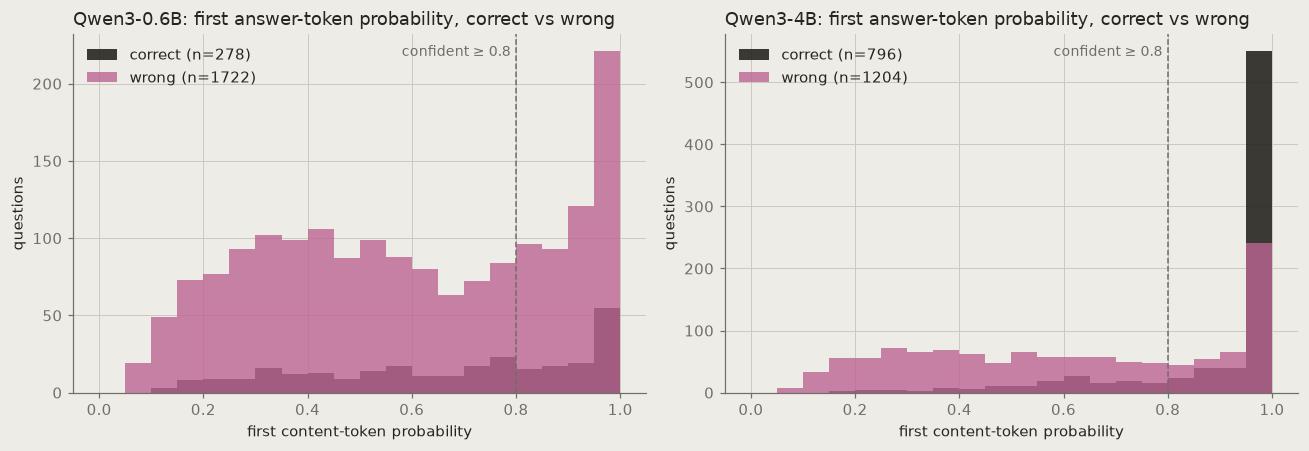

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, (m, d) in zip(axes, REC.items()):
    bins = np.linspace(0, 1, 21)
    ax.hist(d.first_tok_prob[d.correct == 1], bins=bins, color=C_CORRECT, alpha=0.9, label=f"correct (n={int(d.correct.sum())})")
    ax.hist(d.first_tok_prob[d.correct == 0], bins=bins, color=C_WRONG, alpha=0.8, label=f"wrong (n={int((1 - d.correct).sum())})")
    ax.axvline(THRESHOLD, color=MUTED, ls="--", lw=1)
    ax.text(THRESHOLD - 0.01, ax.get_ylim()[1] * 0.97, f"confident ≥ {THRESHOLD}", color=MUTED, ha="right", va="top", fontsize=9)
    ax.set_title(f"{m}: first answer-token probability, correct vs wrong"); ax.set_xlabel("first content-token probability"); ax.set_ylabel("questions")
    ax.legend(loc="upper left")
save(fig, "01_confidence_hist")

**Read:** the right-hand bar is the story. At 0.6B the top bin is mostly wrong: the model is confidently fabricating. At 4B the top bin is mostly right, but there is a solid pink block inside it. Those are the confident errors. No threshold on this axis separates them from the confident-correct answers next to them.

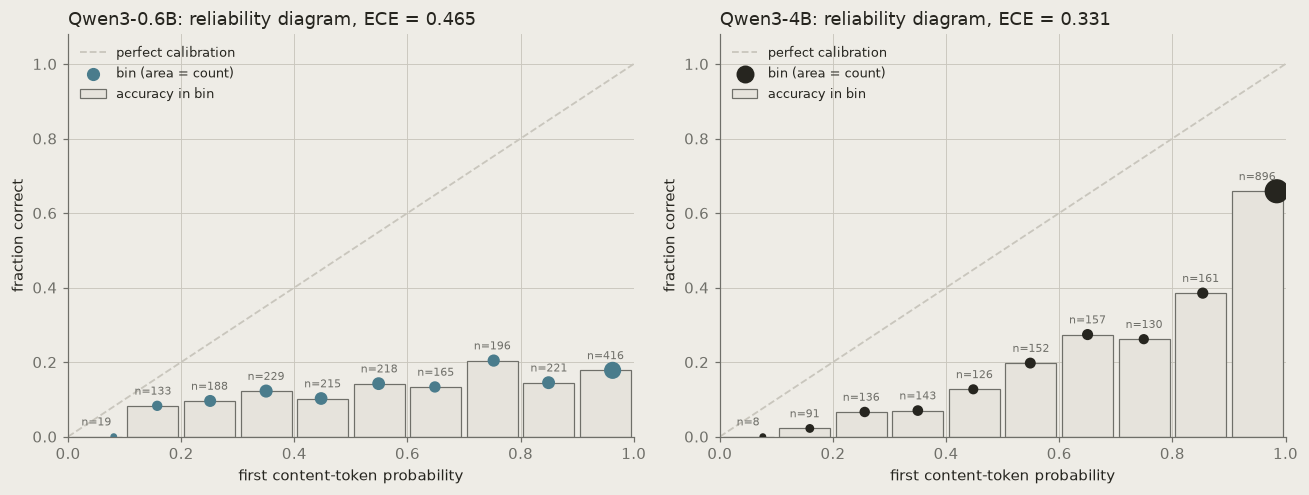

In [ ]:
def reliability(d, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(d.first_tok_prob, edges) - 1, 0, n_bins - 1)
    rows = []
    for b in range(n_bins):
        sel = idx == b
        if sel.sum() == 0: continue
        rows.append({"bin_mid": (edges[b] + edges[b + 1]) / 2, "mean_conf": d.first_tok_prob[sel].mean(),
                     "accuracy": d.correct[sel].mean(), "n": int(sel.sum())})
    r = pd.DataFrame(rows)
    ece = float((r.n / r.n.sum() * (r.mean_conf - r.accuracy).abs()).sum())
    return r, ece

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (m, d) in zip(axes, REC.items()):
    r, ece = reliability(d)
    ax.plot([0, 1], [0, 1], color=RULE, lw=1.2, ls="--", label="perfect calibration")
    ax.bar(r.bin_mid, r.accuracy, width=0.09, color=CARD, edgecolor=MUTED, lw=0.8, label="accuracy in bin")
    ax.scatter(r.mean_conf, r.accuracy, s=np.clip(r.n / 4, 12, 220), color=MODEL_COLORS[m], zorder=3, label="bin (area = count)")
    for _, row in r.iterrows():
        ax.text(row.bin_mid, row.accuracy + 0.03, f"n={int(row.n)}", ha="center", fontsize=7.5, color=MUTED)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.08)
    ax.set_title(f"{m}: reliability diagram, ECE = {ece:.3f}"); ax.set_xlabel("first content-token probability"); ax.set_ylabel("fraction correct")
    ax.legend(loc="upper left", fontsize=8.5)
save(fig, "02_calibration")

**Read:** both models sit below the diagonal everywhere, so both are overconfident. The gap at the top bin is the fraction of confident answers that are wrong: roughly 80% at 0.6B and about a third at 4B. Scale helps but does not remove it. (Expected calibration error, ECE, is the count-weighted mean gap.)

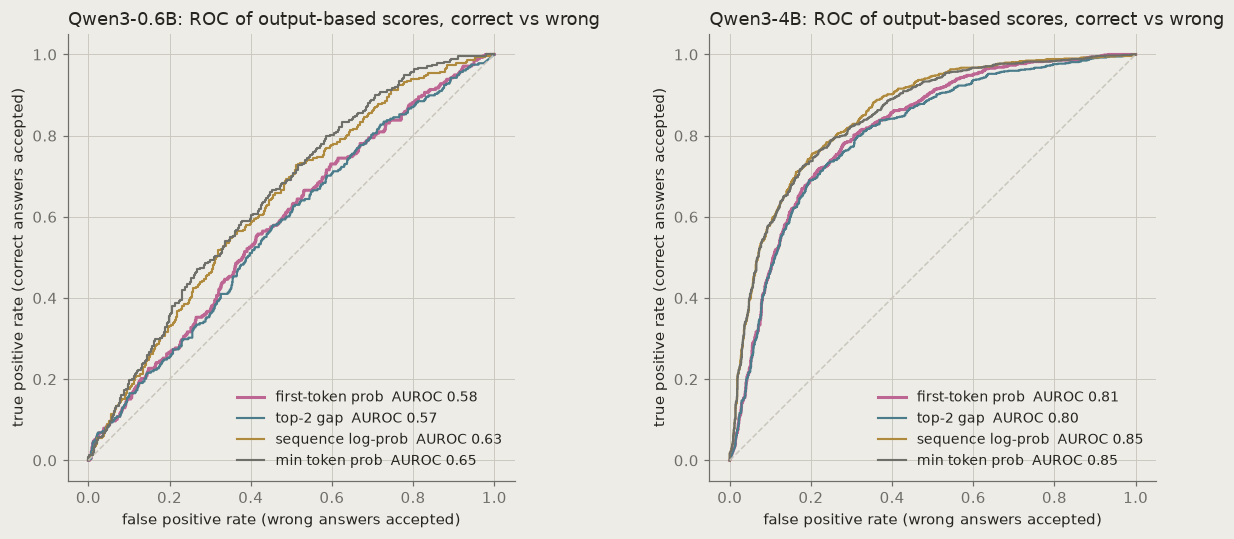

AUROC all          AUROC confident subset         
model             Qwen3-0.6B Qwen3-4B             Qwen3-0.6B Qwen3-4B
score                                                                
first-token prob       0.581    0.814                  0.554    0.678
min token prob         0.648    0.848                  0.621    0.768
sequence log-prob      0.632    0.853                  0.618    0.770
top-2 gap              0.573    0.805                  0.540    0.670

In [4]:
SCORES = {"first_tok_prob": "first-token prob", "top2_gap": "top-2 gap", "seq_logprob": "sequence log-prob", "min_tok_prob": "min token prob"}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
rows = []
for ax, (m, d) in zip(axes, REC.items()):
    for s, name in SCORES.items():
        fpr, tpr, _ = roc_curve(d.correct, d[s]); a = auroc(d.correct, d[s])
        a_conf = auroc(d.correct[d.confident], d[s][d.confident])
        ax.plot(fpr, tpr, color=SCORE_COLORS[s], lw=2 if s == "first_tok_prob" else 1.4, label=f"{name}  AUROC {a:.2f}")
        rows.append({"model": m, "score": name, "AUROC all": a, "AUROC confident subset": a_conf})
    ax.plot([0, 1], [0, 1], color=RULE, lw=1, ls="--"); ax.set_aspect("equal")
    ax.set_title(f"{m}: ROC of output-based scores, correct vs wrong"); ax.set_xlabel("false positive rate (wrong answers accepted)"); ax.set_ylabel("true positive rate (correct answers accepted)")
    ax.legend(loc="lower right", fontsize=9)
save(fig, "03_roc_output_scores")
output_auroc = pd.DataFrame(rows)
output_auroc.pivot(index="score", columns="model", values=["AUROC all", "AUROC confident subset"]).round(3)

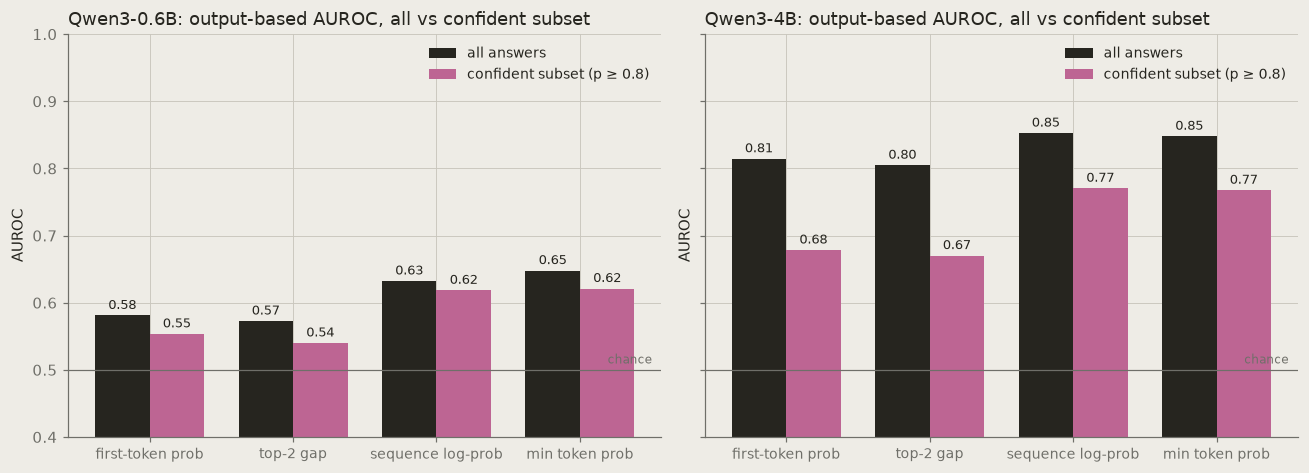

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, m in zip(axes, REC):
    sub = output_auroc[output_auroc.model == m]
    x = np.arange(len(sub)); w = 0.38
    b1 = ax.bar(x - w / 2, sub["AUROC all"], w, color=INK, label="all answers")
    b2 = ax.bar(x + w / 2, sub["AUROC confident subset"], w, color=ACCENT, label=f"confident subset (p ≥ {THRESHOLD})")
    label_bars(ax, b1); label_bars(ax, b2)
    ax.axhline(0.5, color=MUTED, lw=0.8); ax.text(len(sub) - 0.5, 0.505, "chance", color=MUTED, fontsize=8, ha="right", va="bottom")
    ax.set_xticks(x); ax.set_xticklabels(sub.score, rotation=0, fontsize=9); ax.set_ylim(0.4, 1.0)
    ax.set_title(f"{m}: output-based AUROC, all vs confident subset"); ax.set_ylabel("AUROC")
    ax.legend(loc="upper right", fontsize=9)
save(fig, "04_output_auroc_all_vs_confident")

**Read:** every output-based score drops when restricted to confident answers, because the score itself is what defined the subset. On 0.6B the first-token probability is at chance inside the confident set (0.55). On 4B it keeps some signal (0.68) because the confident range still has spread between 0.8 and 1.0. Sequence log-prob is the best overall on 4B. This table is the baseline that Phases 2 and 4 must beat.

Orientation, not comparison: Orgad et al. report logit-based baselines around 0.6 to 0.7 AUROC on TriviaQA for Mistral-7B, with probes at 0.8 and above. Our 4B numbers are in that band.

## Phase 2. Does sampling disagreement (semantic entropy) know?

**What this computes.** For the first 500 questions per model, 5 answers sampled at temperature 1.0. Answers are grouped into meaning clusters and the entropy over cluster frequencies is the semantic entropy (SE). High SE means the model gives different answers to the same question. Script: `src/pilot/run_semantic_entropy.py`.

**What it mirrors.** Farquhar et al., *Nature* 2024, discrete semantic entropy, TriviaQA being one of their datasets. One simplification: they cluster with a bidirectional entailment model; our answers are two or three words, so we cluster by normalized string match, with all gold-alias matches sharing one cluster. For short answers this is close to what entailment would do, and it cannot inflate SE.

**Why it matters.** SE is the strongest published output-side monitor and the review's representative of "hallucination as uncertainty." Its authors scope it to *confabulations*, arbitrary wrong answers that vary between samples. A model that gives the same wrong answer five times out of five has SE of exactly zero. The prediction going in: a large share of confident errors look like that, so SE should be close to blind on the confident subset. The data below says that prediction is only half right.

In [6]:
def load_se(run):
    p = ROOT / "results" / run / "semantic_entropy.jsonl"
    if not p.exists(): return None
    se = pd.read_json(p, lines=True)
    return se.merge(REC[[k for k, v in RUNS.items() if v == run][0]], on="qid", how="inner")

SE = {m: load_se(r) for m, r in RUNS.items()}
for m, s in SE.items():
    print(m, "semantic-entropy records:", 0 if s is None else len(s))
SE = {m: s for m, s in SE.items() if s is not None and len(s) > 0}

Qwen3-0.6B semantic-entropy records: 500
Qwen3-4B semantic-entropy records: 500


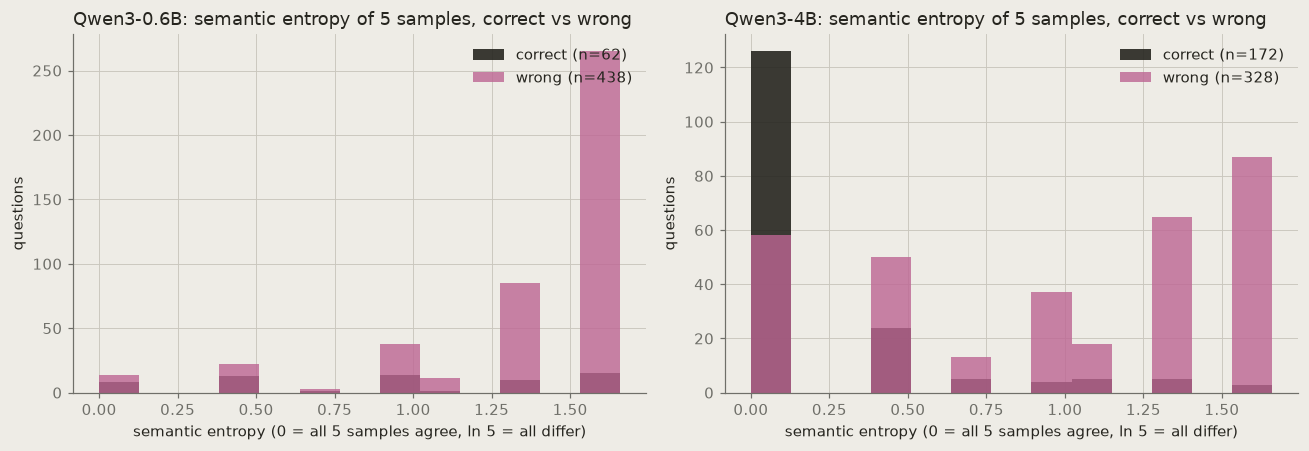

In [7]:
fig, axes = plt.subplots(1, len(SE), figsize=(6 * len(SE), 4.2), squeeze=False); axes = axes[0]
for ax, (m, s) in zip(axes, SE.items()):
    bins = np.linspace(0, math.log(5) + 0.05, 14)
    ax.hist(s.semantic_entropy[s.correct == 1], bins=bins, color=C_CORRECT, alpha=0.9, label=f"correct (n={int(s.correct.sum())})")
    ax.hist(s.semantic_entropy[s.correct == 0], bins=bins, color=C_WRONG, alpha=0.8, label=f"wrong (n={int((1 - s.correct).sum())})")
    ax.set_title(f"{m}: semantic entropy of 5 samples, correct vs wrong"); ax.set_xlabel("semantic entropy (0 = all 5 samples agree, ln 5 = all differ)"); ax.set_ylabel("questions")
    ax.legend(loc="upper right")
save(fig, "05_semantic_entropy_hist")

**Read:** wrong answers skew toward high entropy, which is Farquhar's result. But look at the zero bin: those are answers the model gives identically every time. Pink in that bin is a confabulation detector's blind spot by construction.

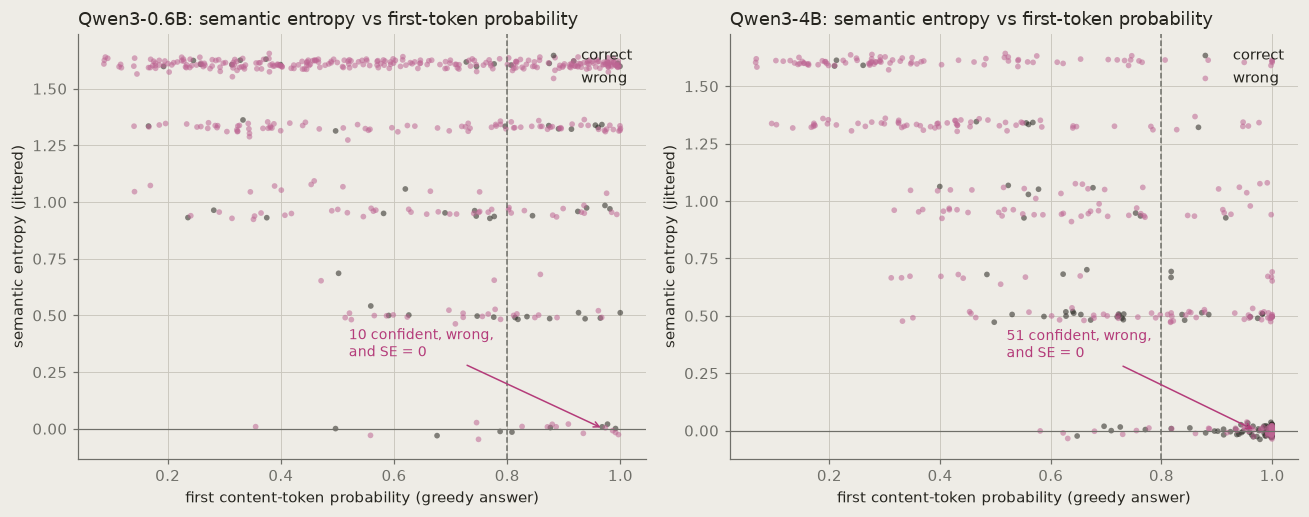

In [8]:
fig, axes = plt.subplots(1, len(SE), figsize=(6 * len(SE), 4.8), squeeze=False); axes = axes[0]
rng = np.random.default_rng(0)
for ax, (m, s) in zip(axes, SE.items()):
    jit = rng.normal(0, 0.015, len(s))
    for lab, c, name in [(1, C_CORRECT, "correct"), (0, C_WRONG, "wrong")]:
        sel = s.correct == lab
        ax.scatter(s.first_tok_prob[sel], s.semantic_entropy[sel] + jit[sel], s=14, color=c, alpha=0.55, label=name, edgecolors="none")
    ax.axvline(THRESHOLD, color=MUTED, ls="--", lw=1); ax.axhline(0, color=MUTED, lw=0.8)
    n_blind = int(((s.first_tok_prob >= THRESHOLD) & (s.semantic_entropy == 0) & (s.correct == 0)).sum())
    ax.annotate(f"{n_blind} confident, wrong,\nand SE = 0", xy=(0.97, 0.0), xytext=(0.52, 0.32), fontsize=9, color=ACCENT_TEXT,
                arrowprops=dict(arrowstyle="->", color=ACCENT_TEXT, lw=1))
    ax.set_title(f"{m}: semantic entropy vs first-token probability"); ax.set_xlabel("first content-token probability (greedy answer)"); ax.set_ylabel("semantic entropy (jittered)")
    ax.legend(loc="upper right")
save(fig, "06_se_vs_tokenprob_scatter")

**Read:** the two signals agree on the easy region (low probability, high entropy, mostly wrong). The surprise is the right-hand column: plenty of confident greedy answers are *unstable* under sampling, and those are disproportionately wrong. SE sees them; token probability does not. The bottom-right corner, high probability and zero entropy, is where both go quiet, and it still holds a pink population.

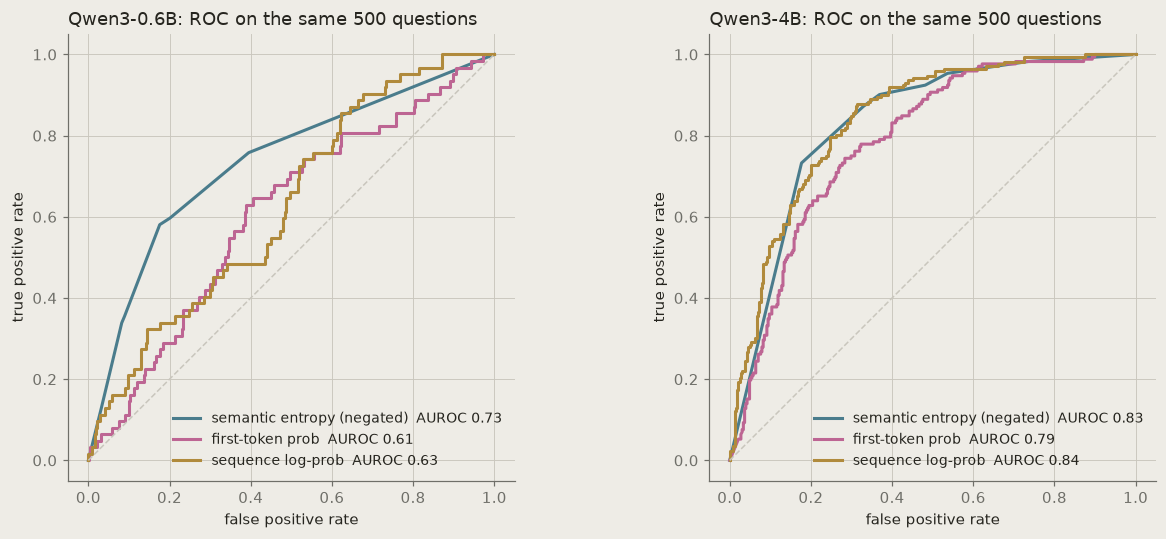

,model,score,n,AUROC all,AUROC confident,conf CI lo,conf CI hi,n confident
0,Qwen3-0.6B,semantic entropy (negated),500,0.735,0.752,0.656,0.842,172
1,Qwen3-0.6B,first-token prob,500,0.610,0.506,0.393,0.627,172
2,Qwen3-0.6B,sequence log-prob,500,0.629,0.618,0.506,0.722,172
3,Qwen3-4B,semantic entropy (negated),500,0.831,0.726,0.670,0.779,244
4,Qwen3-4B,first-token prob,500,0.788,0.624,0.556,0.687,244
5,Qwen3-4B,sequence log-prob,500,0.842,0.737,0.674,0.798,244


In [9]:
rows = []
fig, axes = plt.subplots(1, len(SE), figsize=(6 * len(SE), 5), squeeze=False); axes = axes[0]
for ax, (m, s) in zip(axes, SE.items()):
    conf = s.confident
    for score, sign, c, name in [("semantic_entropy", -1, "#4a7c8c", "semantic entropy (negated)"), ("first_tok_prob", 1, ACCENT, "first-token prob"), ("seq_logprob", 1, "#b08a3c", "sequence log-prob")]:
        v = sign * s[score]
        fpr, tpr, _ = roc_curve(s.correct, v); a = auroc(s.correct, v); a_c = auroc(s.correct[conf], v[conf])
        lo, hi = boot_ci(s.correct[conf], v[conf])
        ax.plot(fpr, tpr, color=c, lw=2, label=f"{name}  AUROC {a:.2f}")
        rows.append({"model": m, "score": name, "n": len(s), "AUROC all": a, "AUROC confident": a_c, "conf CI lo": lo, "conf CI hi": hi, "n confident": int(conf.sum())})
    ax.plot([0, 1], [0, 1], color=RULE, lw=1, ls="--"); ax.set_aspect("equal")
    ax.set_title(f"{m}: ROC on the same {len(s)} questions"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(loc="lower right", fontsize=9)
save(fig, "07_roc_se_vs_tokenprob")
se_auroc = pd.DataFrame(rows); se_auroc.round(3)

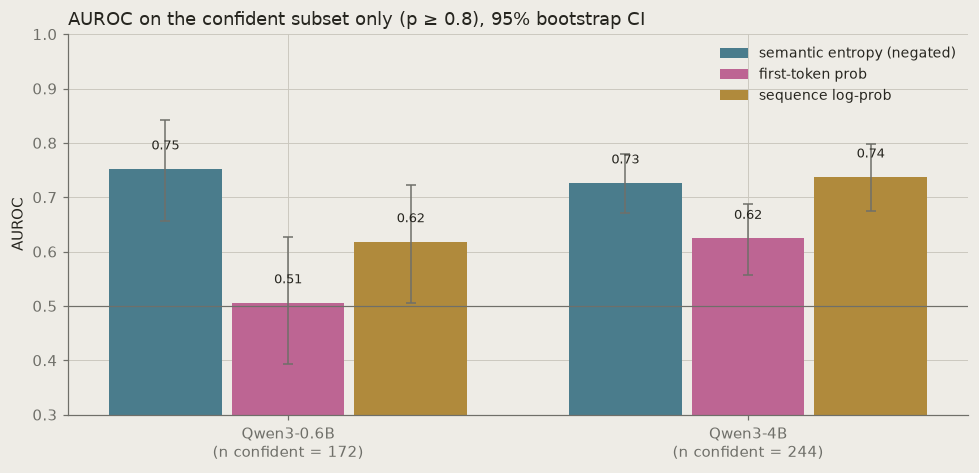

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.4))
models = list(SE); scores = se_auroc.score.unique(); w = 0.8 / len(scores)
cols = {"semantic entropy (negated)": "#4a7c8c", "first-token prob": ACCENT, "sequence log-prob": "#b08a3c"}
for i, sc in enumerate(scores):
    sub = se_auroc[se_auroc.score == sc].set_index("model").loc[models]
    x = np.arange(len(models)) + (i - (len(scores) - 1) / 2) * w
    err = np.vstack([sub["AUROC confident"] - sub["conf CI lo"], sub["conf CI hi"] - sub["AUROC confident"]])
    b = ax.bar(x, sub["AUROC confident"], w * 0.92, color=cols[sc], yerr=err, capsize=3, error_kw=dict(ecolor=MUTED, lw=1), label=sc)
    label_bars(ax, b, dy=0.03)
ax.axhline(0.5, color=MUTED, lw=0.8); ax.set_ylim(0.3, 1.0)
ax.set_xticks(np.arange(len(models))); ax.set_xticklabels([f"{m}\n(n confident = {int(se_auroc[se_auroc.model == m]['n confident'].iloc[0])})" for m in models])
ax.set_title(f"AUROC on the confident subset only (p ≥ {THRESHOLD}), 95% bootstrap CI"); ax.set_ylabel("AUROC"); ax.legend(loc="upper right", fontsize=9)
save(fig, "08_se_auroc_confident_subset")

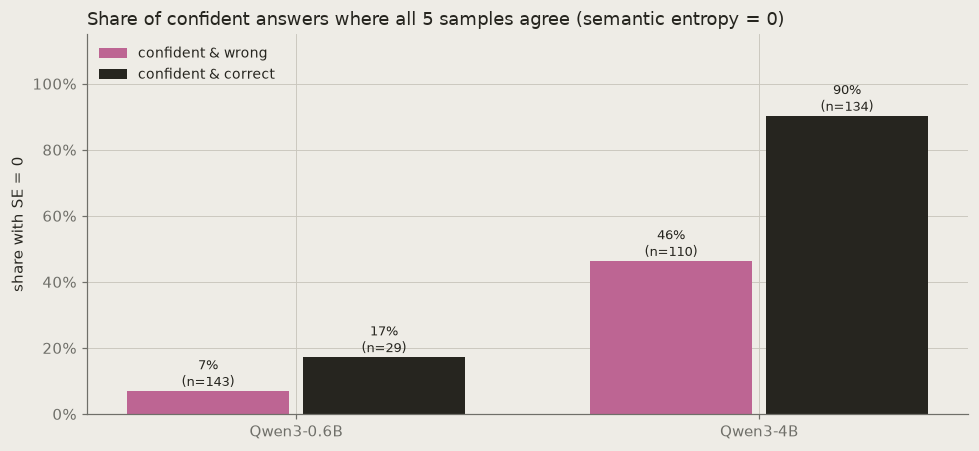

,model,group,n,SE = 0 share
0,Qwen3-0.6B,confident & wrong,143,0.069930
1,Qwen3-0.6B,confident & correct,29,0.172414
2,Qwen3-4B,confident & wrong,110,0.463636
3,Qwen3-4B,confident & correct,134,0.902985


In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
rows = []
for m, s in SE.items():
    for lab, name in [(0, "confident & wrong"), (1, "confident & correct")]:
        sel = s.confident & (s.correct == lab)
        rows.append({"model": m, "group": name, "n": int(sel.sum()), "SE = 0 share": float((s.semantic_entropy[sel] == 0).mean()) if sel.sum() else np.nan})
blind = pd.DataFrame(rows)
x = np.arange(len(SE)); w = 0.38
for i, (grp, c) in enumerate([("confident & wrong", C_WRONG), ("confident & correct", C_CORRECT)]):
    sub = blind[blind.group == grp].set_index("model").loc[list(SE)]
    b = ax.bar(x + (i - 0.5) * w, sub["SE = 0 share"], w * 0.92, color=c, label=grp)
    for bb, n in zip(b, sub.n): ax.text(bb.get_x() + bb.get_width() / 2, bb.get_height() + 0.015, f"{bb.get_height():.0%}\n(n={n})", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(list(SE)); ax.set_ylim(0, 1.15); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Share of confident answers where all 5 samples agree (semantic entropy = 0)"); ax.set_ylabel("share with SE = 0"); ax.legend(loc="upper left", fontsize=9)
save(fig, "09_se_zero_share")
blind

**Read:** the prediction was that most confident errors would sit in the zero-entropy bin. They do not. At 4B, confident-correct answers are stable 90% of the time and confident-wrong answers only 46% of the time, which is exactly why SE beats token probability on the confident subset in the previous figure. At 0.6B almost nothing is stable, so "confident" by first-token probability does not mean certain in any meaningful sense for that model; its greedy confidence is a poor proxy for model certainty.

So the honest statement for the review: semantic entropy recovers about half of the confident errors that token probability misses. The pink bar is the other half: answers the model gives identically every time and that are wrong. Farquhar et al. scope SE to confabulations and exclude exactly this population. That is the CHOKE-shaped blind spot, and it is the subset Phase 4 has to target.

Orientation: Farquhar et al. report SE ahead of naive entropy and p(True) on TriviaQA across LLaMA-2, Falcon and Mistral models (their Fig. 2; check exact values against the paper before quoting). Our run uses 5 samples instead of 10, string clustering instead of entailment, and 500 questions, so CIs are wide.

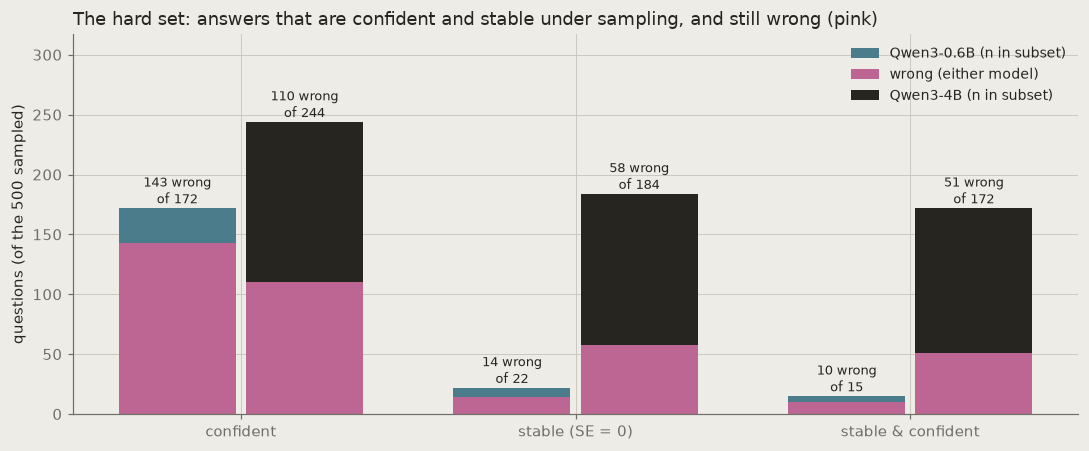

,model,subset,n,wrong,share wrong,token-prob AUROC
0,Qwen3-0.6B,confident,172,143,0.831,0.506
1,Qwen3-0.6B,stable (SE = 0),22,14,0.636,0.455
2,Qwen3-0.6B,stable & confident,15,10,0.667,0.480
3,Qwen3-4B,confident,244,110,0.451,0.624
4,Qwen3-4B,stable (SE = 0),184,58,0.315,0.577
5,Qwen3-4B,stable & confident,172,51,0.297,0.543


In [12]:
rows = []
for m, s in SE.items():
    stable = s.semantic_entropy == 0
    for name, sel in [("confident", s.confident), ("stable (SE = 0)", stable), ("stable & confident", stable & s.confident)]:
        sub = s[sel]
        rows.append({"model": m, "subset": name, "n": int(sel.sum()), "wrong": int((sub.correct == 0).sum()), "share wrong": float((sub.correct == 0).mean()) if sel.sum() else np.nan,
                     "token-prob AUROC": auroc(sub.correct, sub.first_tok_prob) if sel.sum() else np.nan})
hard = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.2))
subsets = hard.subset.unique(); x = np.arange(len(subsets)); w = 0.38
for i, m in enumerate(SE):
    sub = hard[hard.model == m].set_index("subset").loc[subsets]
    b = ax.bar(x + (i - 0.5) * w, sub.n, w * 0.92, color=MODEL_COLORS[m], label=f"{m} (n in subset)")
    ax.bar(x + (i - 0.5) * w, sub.wrong, w * 0.92, color=ACCENT, label="wrong (either model)" if i == 0 else None)
    for bb, n, wr in zip(b, sub.n, sub.wrong): ax.text(bb.get_x() + bb.get_width() / 2, n + 4, f"{wr} wrong\nof {n}", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(subsets); ax.set_ylim(0, hard.n.max() * 1.3)
ax.set_title("The hard set: answers that are confident and stable under sampling, and still wrong (pink)"); ax.set_ylabel("questions (of the 500 sampled)"); ax.legend(loc="upper right", fontsize=9)
save(fig, "09b_hard_set")
hard.round(3)

**Read:** the last pair of bars is the population the review is about. Every output-side signal is exhausted on it by definition: probability is high, samples agree, and token probability inside it is at chance (see the table). Whether the residual stream still separates the pink from the dark part of that bar is the question Phase 4 answers. At 0.6B the hard set is 15 questions, because that model is unstable under temperature-1 sampling almost everywhere, so the hard-set test belongs on 4B.

## Phase 3. How large is the confident-and-wrong population?

**What this computes.** The two-by-two: knows vs does not, certain vs uncertain. Counts per quadrant, how the confident-error count depends on the threshold, which errors persist from 0.6B to 4B, how many labels hinge on lexical matching, and a sample of confident errors to read by eye.

**What it mirrors.** The existence claim of CHOKE (Simhi et al., 2025): high-certainty hallucinations are a stable, sizeable population, not noise. It does *not* mirror their paired-perturbation protocol that separates "knows but answered wrong" (HK+) from "never knew" (HK−). That is the Nov 6 experiment.

**Why it matters.** Phases 1 and 2 showed output-side monitors go blind on confident answers. This phase shows the blind spot is big enough to care about in our own setup, with our own labels, and then shows how far to trust those labels.

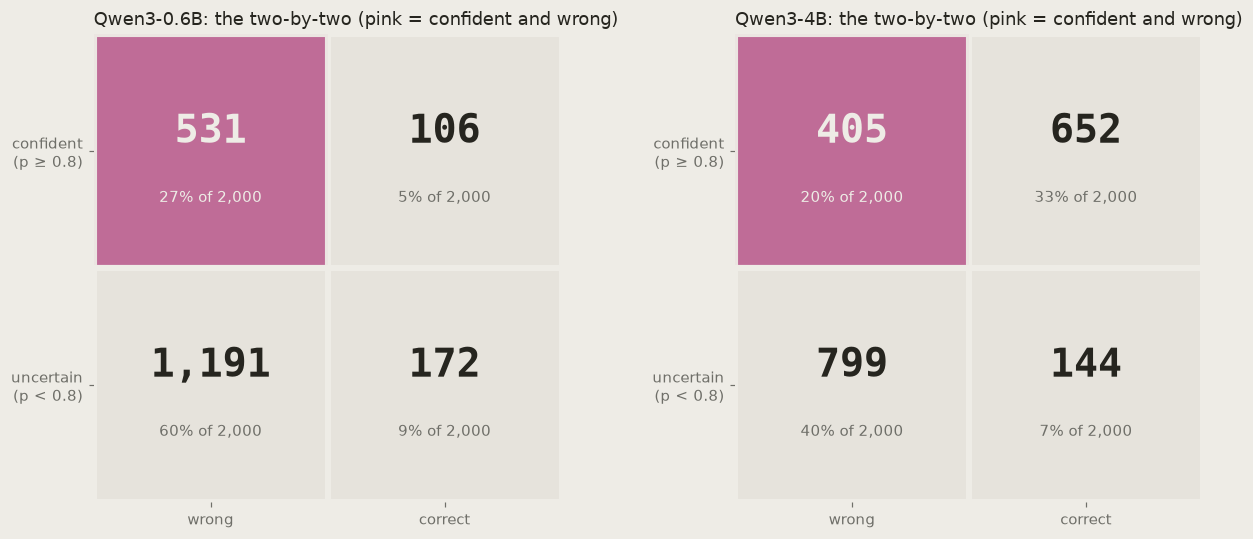

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (m, d) in zip(axes, REC.items()):
    n = len(d)
    q = {(1, 1): int((d.confident & (d.correct == 1)).sum()), (1, 0): int((d.confident & (d.correct == 0)).sum()),
         (0, 1): int((~d.confident & (d.correct == 1)).sum()), (0, 0): int((~d.confident & (d.correct == 0)).sum())}
    for (conf, corr), cnt in q.items():
        x, y = corr, conf
        face = ACCENT if (conf, corr) == (1, 0) else CARD
        ax.add_patch(plt.Rectangle((x, y), 1, 1, facecolor=face, edgecolor=PAPER, lw=4, alpha=0.95 if face == ACCENT else 1))
        ax.text(x + 0.5, y + 0.58, f"{cnt:,}", ha="center", va="center", fontsize=26, fontweight="bold", color=PAPER if face == ACCENT else INK, family="monospace")
        ax.text(x + 0.5, y + 0.3, f"{cnt / n:.0%} of {n:,}", ha="center", va="center", fontsize=10, color=PAPER if face == ACCENT else MUTED)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(["wrong", "correct"]); ax.set_yticks([0.5, 1.5]); ax.set_yticklabels([f"uncertain\n(p < {THRESHOLD})", f"confident\n(p ≥ {THRESHOLD})"])
    ax.grid(False); ax.set_aspect("equal"); ax.set_title(f"{m}: the two-by-two (pink = confident and wrong)")
    for s in ("left", "bottom"): ax.spines[s].set_visible(False)
save(fig, "10_quadrants")

**Read:** the pink box is the population every monitor in Phases 1 and 2 waves through. Scale moves mass from the bottom-left to the top-right, as it should, but the pink box shrinks slowly: 531 to 405 questions, 27% to 20% of the set. Gate A asked for at least 150. Both models clear it by a wide margin.

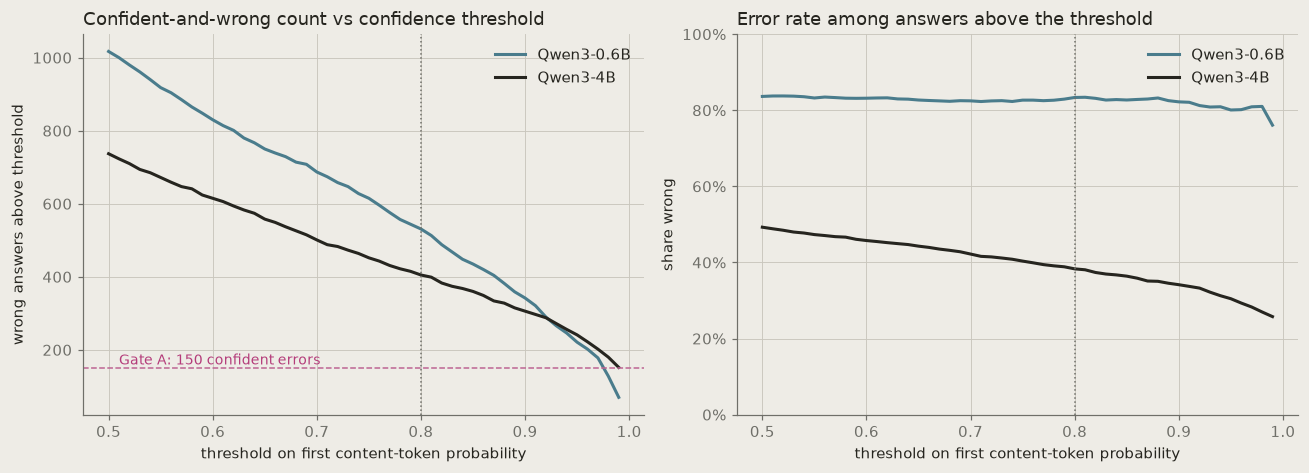

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ths = np.linspace(0.5, 0.99, 50)
ax = axes[0]
for m, d in REC.items():
    ax.plot(ths, [int(((d.first_tok_prob >= t) & (d.correct == 0)).sum()) for t in ths], color=MODEL_COLORS[m], lw=2, label=m)
ax.axhline(150, color=ACCENT, ls="--", lw=1); ax.text(0.51, 160, "Gate A: 150 confident errors", color=ACCENT_TEXT, fontsize=9)
ax.axvline(THRESHOLD, color=MUTED, ls=":", lw=1)
ax.set_title("Confident-and-wrong count vs confidence threshold"); ax.set_xlabel("threshold on first content-token probability"); ax.set_ylabel("wrong answers above threshold"); ax.legend()
ax = axes[1]
for m, d in REC.items():
    ax.plot(ths, [1 - d.correct[d.first_tok_prob >= t].mean() for t in ths], color=MODEL_COLORS[m], lw=2, label=m)
ax.axvline(THRESHOLD, color=MUTED, ls=":", lw=1); ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Error rate among answers above the threshold"); ax.set_xlabel("threshold on first content-token probability"); ax.set_ylabel("share wrong"); ax.legend()
save(fig, "11_threshold_sweep")

**Read:** the 0.8 cut is not doing the work. At 0.6B the error rate among confident answers barely moves as the threshold tightens, which means the model is just as wrong at p = 0.95 as at p = 0.8. At 4B it falls slowly. Raising the bar does not buy out of the problem.

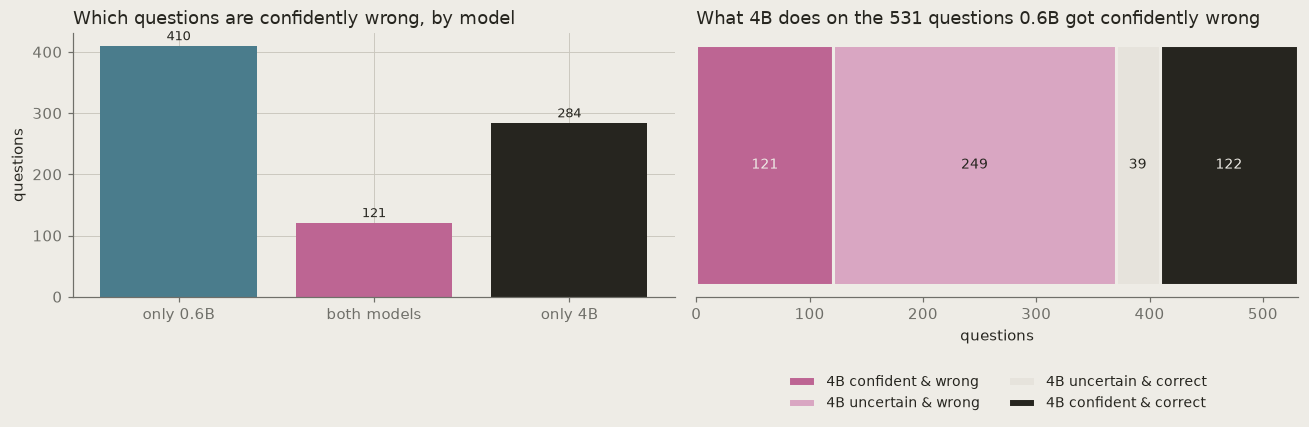

In [15]:
a, b = REC["Qwen3-0.6B"], REC["Qwen3-4B"]
cw = {m: set(d.qid[d.confident & (d.correct == 0)]) for m, d in REC.items()}
both = cw["Qwen3-0.6B"] & cw["Qwen3-4B"]; only_s = cw["Qwen3-0.6B"] - both; only_l = cw["Qwen3-4B"] - both
# what 4B does on questions 0.6B got confidently wrong
b_on = b.set_index("qid").loc[list(cw["Qwen3-0.6B"])]
fate = {"4B confident & wrong": int((b_on.confident & (b_on.correct == 0)).sum()), "4B uncertain & wrong": int((~b_on.confident & (b_on.correct == 0)).sum()),
        "4B uncertain & correct": int((~b_on.confident & (b_on.correct == 1)).sum()), "4B confident & correct": int((b_on.confident & (b_on.correct == 1)).sum())}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
bars = ax.bar(["only 0.6B", "both models", "only 4B"], [len(only_s), len(both), len(only_l)], color=[MODEL_COLORS["Qwen3-0.6B"], ACCENT, MODEL_COLORS["Qwen3-4B"]])
label_bars(ax, bars, fmt="{:.0f}", dy=4); ax.set_title("Which questions are confidently wrong, by model"); ax.set_ylabel("questions")
ax = axes[1]
cols = [ACCENT, "#d9a6c2", CARD, INK]
left = 0
for (k, v), c in zip(fate.items(), cols):
    ax.barh([0], [v], left=left, color=c, edgecolor=PAPER, lw=2, label=k)
    if v > 25: ax.text(left + v / 2, 0, f"{v}", ha="center", va="center", fontsize=9, color=PAPER if c in (ACCENT, INK) else INK)
    left += v
ax.set_yticks([]); ax.set_xlim(0, left); ax.grid(False); ax.spines["left"].set_visible(False)
ax.set_title(f"What 4B does on the {len(cw['Qwen3-0.6B'])} questions 0.6B got confidently wrong"); ax.set_xlabel("questions"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, fontsize=9)
save(fig, "12_persistence_across_scale")

**Read:** scale mostly turns confident errors into *uncertain* errors (249 of 531), fixes fewer than a third (161), and leaves 121 still confidently wrong. Meanwhile 284 of 4B's 405 confident errors are new. Confident errors are a stable phenomenon on a moving set of items, which is what CHOKE reports across model families.

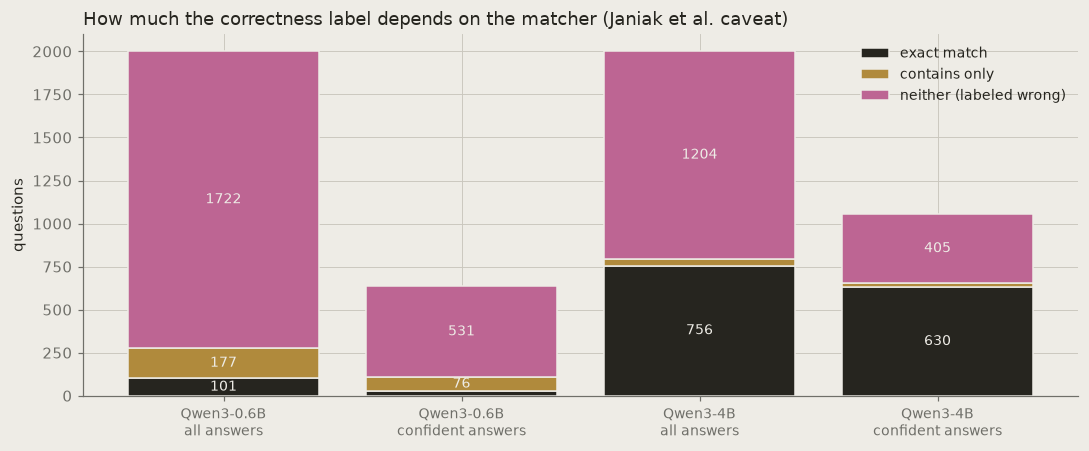

,model,group,exact match,contains only,neither (labeled wrong)
0,Qwen3-0.6B,all answers,101,177,1722
1,Qwen3-0.6B,confident answers,30,76,531
2,Qwen3-4B,all answers,756,40,1204
3,Qwen3-4B,confident answers,630,22,405


In [16]:
rows = []
for m, d in REC.items():
    for grp, sel in [("all answers", np.ones(len(d), bool)), ("confident answers", d.confident.values)]:
        sub = d[sel]
        rows.append({"model": m, "group": grp, "exact match": int(sub.exact_match.sum()), "contains only": int((sub.contains_match & ~sub.exact_match).sum()), "neither (labeled wrong)": int((~sub.contains_match).sum())})
lab = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(lab)); cols = {"exact match": INK, "contains only": "#b08a3c", "neither (labeled wrong)": ACCENT}
bottom = np.zeros(len(lab))
for k, c in cols.items():
    bars = ax.bar(x, lab[k], bottom=bottom, color=c, label=k, edgecolor=PAPER, lw=1)
    for bb, v, bt in zip(bars, lab[k], bottom):
        if v > 40: ax.text(bb.get_x() + bb.get_width() / 2, bt + v / 2, str(v), ha="center", va="center", fontsize=9, color=PAPER)
    bottom += lab[k].values
ax.set_xticks(x); ax.set_xticklabels([f"{r.model}\n{r.group}" for r in lab.itertuples()], fontsize=9)
ax.set_title("How much the correctness label depends on the matcher (Janiak et al. caveat)"); ax.set_ylabel("questions"); ax.legend(loc="upper right", fontsize=9)
save(fig, "13_label_sensitivity")
lab

**Read:** the ochre band is answers that are wrong under exact match but right under alias-contains. At 0.6B it is most of the correct labels (177 of 278), because the small model pads answers with words; at 4B it is 5%. Janiak et al. (EMNLP 2025) show lexical labels inflate probe scores, so the honest move is an LLM-judge audit on about 200 items, planned but not done. Until then the pink band is an upper bound on confident errors and the table below is the eyeball check.

In [17]:
pd.set_option("display.max_colwidth", 70)
samples = []
for m, d in REC.items():
    ce = d[d.confident & (d.correct == 0)].sample(8, random_state=0)
    samples.append(ce.assign(model=m)[["model", "question", "gold", "answer", "first_tok_prob"]])
pd.concat(samples).rename(columns={"first_tok_prob": "p(first token)"}).round(2).reset_index(drop=True)

,model,question,gold,answer,p(first token)
0,Qwen3-0.6B,What is the first name of Blackadder in the UK television series ‘...,Edmund,Blackadder,0.91
1,Qwen3-0.6B,To which family of trees do junipers belong?,Cypress,Juniper trees belong to the family of conifers.,0.87
2,Qwen3-0.6B,Who was British Prime Minister between Winston Churchill’s two ter...,Clement Attlee,Winston Churchill,0.88
3,Qwen3-0.6B,Which group released an album in 1986 entitled ‘The Queen is Dead’?,The Smiths,The Queen is Dead,0.95
4,Qwen3-0.6B,Which islands were ceded to Britain by Spain in 1771?,The Falklands,Isle of Man,0.85
5,Qwen3-0.6B,"On a standard dartboard, which number lies between 12 and 20?",5,13,0.93
6,Qwen3-0.6B,"What was the name of the band, featuring members of Thin Lizzy and...",The Greedies (originally The Greedy Bastards),The band is The Who.,0.98
7,Qwen3-0.6B,Where did the Shinning Path terrorists operate?,Peru,The Shinning Path terrorists operated in the United States.,0.99
8,Qwen3-4B,Which kiddies story book character is called Oui Oui in France?,Noddy,Babar,0.83
9,Qwen3-4B,What is the longest river in Canada?,Mackenzie River,St. Lawrence River,0.92


**Read:** eyeballing the sample is the cheapest audit. Typical confident errors on 4B are plausible wrong entities of the right type: a different musical, a different actor. Those are the hard case. Any row where the answer is actually right but phrased differently is a label error, and should be rare in this list if the matcher is doing its job.

### Where Phases 1 to 3 leave the argument

1. Output probability separates right from wrong on average, and is near chance on the confident subset at 0.6B.
2. Semantic entropy does better than expected on the confident subset (0.73 at 4B) because many confident errors are unstable under sampling. It still cannot see the stable half: answers the model repeats every time and gets wrong.
3. The confident-wrong population is 20 to 27% of all questions, does not shrink much with threshold or scale, and roughly half of it at 4B is stable under sampling. That stable, confident, wrong set is the target for Phase 4.

Phase 4 asks whether the residual stream sees what the output does not.

## Phase 4. Does the residual stream know? (linear probes)

**What this computes.** For every layer and two token positions (the last prompt token, and the first generated answer token), a 5-fold out-of-fold L2 logistic-regression probe on the standardized residual stream predicting correct vs wrong, plus a difference-of-means projection (the vector from the mean wrong activation to the mean correct one). AUROC overall, on the confident subset, and on the hard set from Phase 2. Scores are cached to `results/<run>/oof_scores.npz` so the notebook reruns without the 950 MB of activations.

**What it mirrors.** Orgad et al. (2024): probes on exact-answer-token activations beat output-based detection, with a layer sweep. Difference-of-means stands in for the Marks & Tegmark / Bürger et al. "truth direction." Our first-answer-token position is the closest analogue to Orgad's exact-answer token; the last-prompt-token position is the pre-answer state.

**Why it matters.** This is H1. If a linear readout of the hidden state separates confident-correct from confident-wrong better than any output-side score, then the model carries information about its own error that it does not express. If it also works on the stable hard set, where sampling agrees and probability is saturated, it is a signal no output-side monitor can reach.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
N_FOLDS, SEED = 5, 0
FORCE_RECOMPUTE = False
POSITIONS = {"last_prompt": "last_prompt_token.npy", "first_answer": "first_answer_token.npy"}

def oof_scores(x, y):
    probe, dom = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(x, y):
        sc = StandardScaler().fit(x[tr]); xtr, xte = sc.transform(x[tr]), sc.transform(x[te])
        probe[te] = LogisticRegression(C=1.0, max_iter=2000).fit(xtr, y[tr]).decision_function(xte)
        axis = xtr[y[tr] == 1].mean(0) - xtr[y[tr] == 0].mean(0); dom[te] = xte @ axis
    return probe, dom

def load_acts(run, position):
    p = ROOT / "data" / "activations" / run / POSITIONS[position]
    return np.load(p).astype(np.float32) if p.exists() else None

def cached_scores(model, run):
    cache = ROOT / "results" / run / "oof_scores.npz"
    if cache.exists() and not FORCE_RECOMPUTE:
        z = np.load(cache); return {k: z[k] for k in z.files}
    y = REC[model].correct.values; out = {}
    for pos in POSITIONS:
        acts = load_acts(run, pos)
        if acts is None: raise FileNotFoundError(f"no activations for {run}/{pos} and no cache at {cache}")
        L = acts.shape[1]; P, D = np.zeros((L, len(y))), np.zeros((L, len(y)))
        for l in range(L):
            P[l], D[l] = oof_scores(acts[:, l, :], y)
        out[f"probe_{pos}"], out[f"dom_{pos}"] = P, D
        print(f"{model} {pos}: {L} layers done", flush=True)
    np.savez_compressed(cache, **out); return out

SCORES_BY_LAYER = {m: cached_scores(m, r) for m, r in RUNS.items()}
{m: {k: v.shape for k, v in d.items()} for m, d in SCORES_BY_LAYER.items()}

{'Qwen3-0.6B': {'probe_last_prompt': (29, 2000),
  'dom_last_prompt': (29, 2000),
  'probe_first_answer': (29, 2000),
  'dom_first_answer': (29, 2000)},
 'Qwen3-4B': {'probe_last_prompt': (37, 2000),
  'dom_last_prompt': (37, 2000),
  'probe_first_answer': (37, 2000),
  'dom_first_answer': (37, 2000)}}

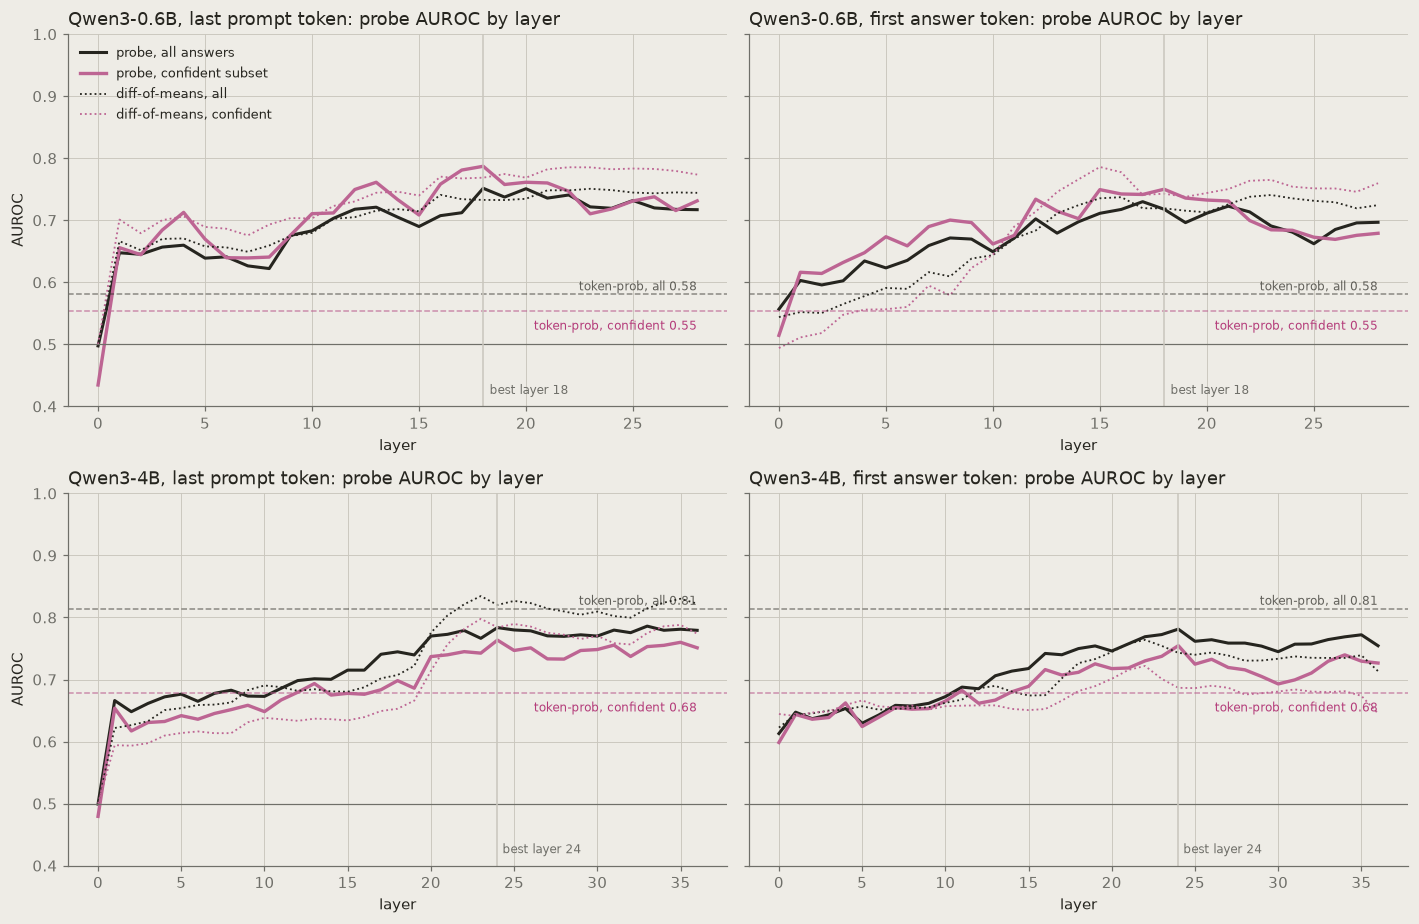

probe all  probe confident  dom all  dom confident
model      position                                                        
Qwen3-0.6B first_answer      0.730            0.750    0.741          0.786
           last_prompt       0.752            0.787    0.751          0.785
Qwen3-4B   first_answer      0.781            0.755    0.764          0.722
           last_prompt       0.786            0.764    0.835          0.798

In [19]:
def layer_table(model):
    d = REC[model]; y = d.correct.values; conf = d.confident.values; rows = []
    for pos in POSITIONS:
        P, D = SCORES_BY_LAYER[model][f"probe_{pos}"], SCORES_BY_LAYER[model][f"dom_{pos}"]
        for l in range(P.shape[0]):
            rows.append({"model": model, "position": pos, "layer": l, "probe all": auroc(y, P[l]), "probe confident": auroc(y[conf], P[l][conf]),
                         "dom all": auroc(y, D[l]), "dom confident": auroc(y[conf], D[l][conf])})
    return pd.DataFrame(rows)
LAYERS = pd.concat([layer_table(m) for m in RUNS])
BEST = {m: {pos: int(g.loc[g["probe confident"].idxmax(), "layer"]) for pos, g in LAYERS[LAYERS.model == m].groupby("position")} for m in RUNS}

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharey=True)
for i, m in enumerate(RUNS):
    d = REC[m]; b_all = auroc(d.correct, d.first_tok_prob); b_conf = auroc(d.correct[d.confident], d.first_tok_prob[d.confident])
    for j, pos in enumerate(POSITIONS):
        ax = axes[i, j]; g = LAYERS[(LAYERS.model == m) & (LAYERS.position == pos)]
        ax.plot(g.layer, g["probe all"], color=INK, lw=2, label="probe, all answers")
        ax.plot(g.layer, g["probe confident"], color=ACCENT, lw=2.2, label="probe, confident subset")
        ax.plot(g.layer, g["dom all"], color=INK, lw=1.2, ls=":", label="diff-of-means, all")
        ax.plot(g.layer, g["dom confident"], color=ACCENT, lw=1.2, ls=":", label="diff-of-means, confident")
        ax.axhline(b_all, color=INK, lw=1, ls="--", alpha=0.5); ax.axhline(b_conf, color=ACCENT, lw=1, ls="--", alpha=0.7); ax.axhline(0.5, color=MUTED, lw=0.8)
        ax.text(g.layer.max(), b_all + 0.006, f"token-prob, all {b_all:.2f}", color=INK, fontsize=8, ha="right", alpha=0.7)
        ax.text(g.layer.max(), b_conf - 0.03, f"token-prob, confident {b_conf:.2f}", color=ACCENT_TEXT, fontsize=8, ha="right")
        bl = BEST[m][pos]; ax.axvline(bl, color=RULE, lw=1); ax.text(bl + 0.3, 0.42, f"best layer {bl}", color=MUTED, fontsize=8)
        ax.set_ylim(0.4, 1.0); ax.set_title(f"{m}, {pos.replace('_', ' ')} token: probe AUROC by layer"); ax.set_xlabel("layer")
        if j == 0: ax.set_ylabel("AUROC")
        if i == 0 and j == 0: ax.legend(loc="upper left", fontsize=8.5)
save(fig, "14_probe_auroc_by_layer")
LAYERS.groupby(["model", "position"])[["probe all", "probe confident", "dom all", "dom confident"]].max().round(3)

**Read:** solid pink is the headline curve. On both models, at both positions, the probe on the confident subset rises above the dashed pink token-probability baseline through the middle layers. On 0.6B, where token probability is at chance on confident answers, the probe reaches about 0.8. On 4B the margin is smaller but the whole upper half of the stack clears the baseline, and the plain difference-of-means direction (dotted pink, 0.80) does slightly better than the probe. Overall (black), the probe does *not* beat token probability on 4B; the internal signal earns its keep only where the output signal runs out. Best layers: 18 of 28 on 0.6B (the layer CSO-LLM selected for this model) and 24 of 36 on 4B, both at about two-thirds depth, which matches Orgad's "middle-to-late layers" finding.

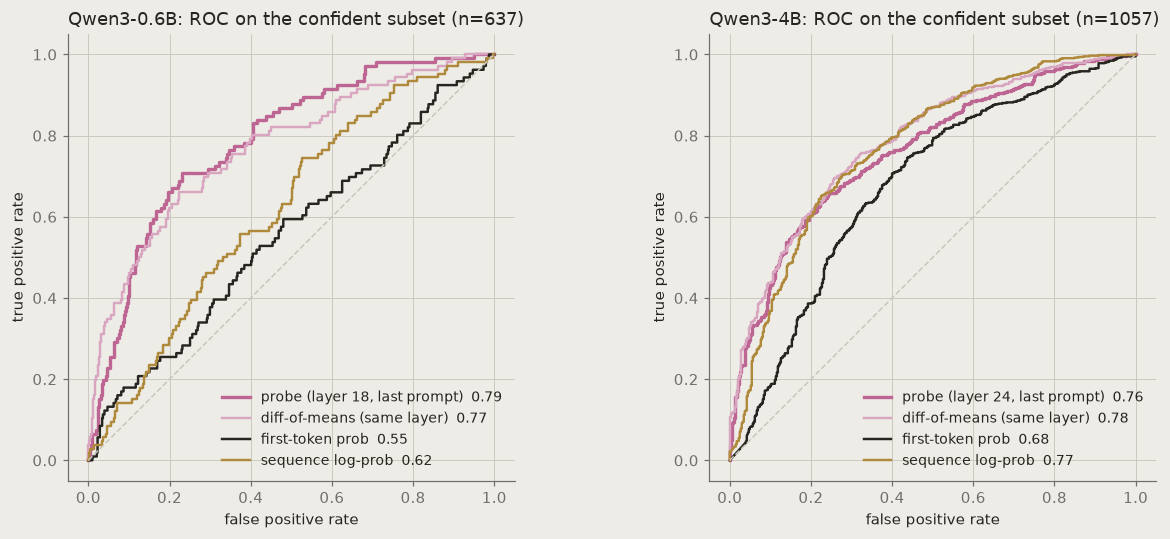

,model,score,AUROC confident,CI lo,CI hi,n
0,Qwen3-0.6B,"probe (layer 18, last prompt)",0.787,0.738,0.832,637
1,Qwen3-0.6B,diff-of-means (same layer),0.769,0.716,0.821,637
2,Qwen3-0.6B,first-token prob,0.554,0.491,0.614,637
3,Qwen3-0.6B,sequence log-prob,0.618,0.567,0.674,637
4,Qwen3-4B,"probe (layer 24, last prompt)",0.764,0.735,0.792,1057
5,Qwen3-4B,diff-of-means (same layer),0.784,0.755,0.814,1057
6,Qwen3-4B,first-token prob,0.678,0.645,0.712,1057
7,Qwen3-4B,sequence log-prob,0.770,0.741,0.799,1057


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5)); rows = []
for ax, m in zip(axes, RUNS):
    d = REC[m]; conf = d.confident.values; y = d.correct.values[conf]; pos = "last_prompt"; bl = BEST[m][pos]
    cands = {"probe (layer %d, %s)" % (bl, pos.replace("_", " ")): SCORES_BY_LAYER[m][f"probe_{pos}"][bl][conf],
             "diff-of-means (same layer)": SCORES_BY_LAYER[m][f"dom_{pos}"][bl][conf],
             "first-token prob": d.first_tok_prob.values[conf], "sequence log-prob": d.seq_logprob.values[conf]}
    cols = [ACCENT, "#d9a6c2", INK, "#b08a3c"]
    for (name, sc), c in zip(cands.items(), cols):
        fpr, tpr, _ = roc_curve(y, sc); a = auroc(y, sc); lo, hi = boot_ci(y, sc)
        ax.plot(fpr, tpr, color=c, lw=2.2 if name.startswith("probe") else 1.6, label=f"{name}  {a:.2f}")
        rows.append({"model": m, "score": name, "AUROC confident": a, "CI lo": lo, "CI hi": hi, "n": int(conf.sum())})
    ax.plot([0, 1], [0, 1], color=RULE, lw=1, ls="--"); ax.set_aspect("equal")
    ax.set_title(f"{m}: ROC on the confident subset (n={int(conf.sum())})"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(loc="lower right", fontsize=9)
save(fig, "15_roc_confident_probe_vs_output")
probe_conf = pd.DataFrame(rows); probe_conf.round(3)

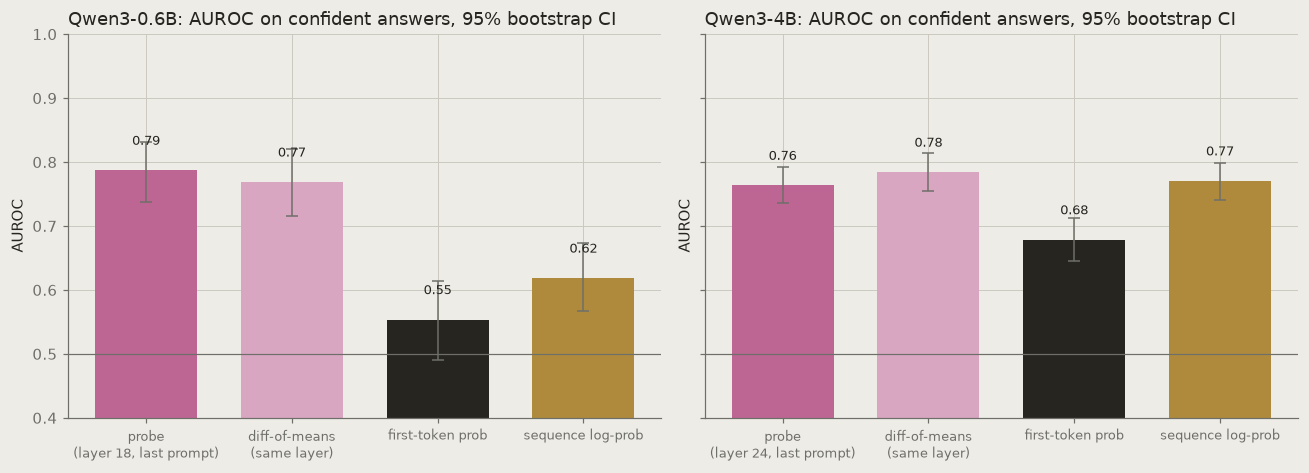

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, m in zip(axes, RUNS):
    sub = probe_conf[probe_conf.model == m].reset_index(drop=True)
    x = np.arange(len(sub)); err = np.vstack([sub["AUROC confident"] - sub["CI lo"], sub["CI hi"] - sub["AUROC confident"]])
    b = ax.bar(x, sub["AUROC confident"], 0.7, color=[ACCENT, "#d9a6c2", INK, "#b08a3c"], yerr=err, capsize=4, error_kw=dict(ecolor=MUTED, lw=1))
    label_bars(ax, b, dy=0.035); ax.axhline(0.5, color=MUTED, lw=0.8); ax.set_ylim(0.4, 1.0)
    ax.set_xticks(x); ax.set_xticklabels([s.replace(" (", "\n(") for s in sub.score], fontsize=8.5)
    ax.set_title(f"{m}: AUROC on confident answers, 95% bootstrap CI"); ax.set_ylabel("AUROC")
save(fig, "16_confident_auroc_ci")

**Read:** H1 as pre-registered: the probe's lower confidence bound must clear 0.55 and the first-token-probability point estimate on the confident subset. It does on both models (0.6B: 0.74 > 0.55; 4B: 0.74 > 0.68). But the honest reading is less tidy. On 4B, sequence log-probability, an output-side score we did not pre-register, reaches 0.77 and ties the probe. So on the confident subset at 4B, "internal beats output" holds against the score that defined the subset but not against every output score. That is why the next figure matters: it moves to the set where *every* output-side score is exhausted.

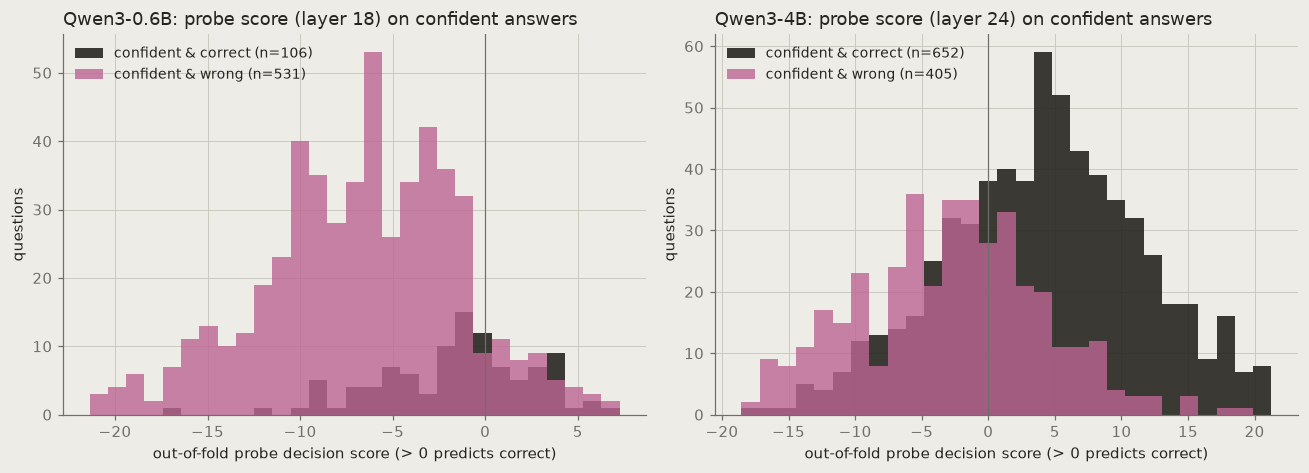

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, m in zip(axes, RUNS):
    d = REC[m]; conf = d.confident.values; pos = "last_prompt"; bl = BEST[m][pos]; sc = SCORES_BY_LAYER[m][f"probe_{pos}"][bl]
    lo, hi = np.percentile(sc[conf], [1, 99]); bins = np.linspace(lo, hi, 30)
    ax.hist(sc[conf & (d.correct == 1)], bins=bins, color=C_CORRECT, alpha=0.9, label=f"confident & correct (n={int((conf & (d.correct == 1)).sum())})")
    ax.hist(sc[conf & (d.correct == 0)], bins=bins, color=C_WRONG, alpha=0.8, label=f"confident & wrong (n={int((conf & (d.correct == 0)).sum())})")
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_title(f"{m}: probe score (layer {bl}) on confident answers"); ax.set_xlabel("out-of-fold probe decision score (> 0 predicts correct)"); ax.set_ylabel("questions"); ax.legend(fontsize=9)
save(fig, "17_probe_score_hist_confident")

**Read:** the same picture as Figure 1, redrawn on the probe's axis instead of the token-probability axis. The two populations that were stacked on top of each other at p ≥ 0.8 now pull apart. Overlap remains, so this is a monitor with a real false-positive rate, not a clean separator.

In [23]:
def probe_within(x, y):
    # probe trained only on the given subset, out-of-fold within it
    return oof_scores(x, y)[0]

rows = []; HARD_SCORES = {}
for m, run in RUNS.items():
    if m not in SE: continue
    d = REC[m]; s = SE[m]; pos = "last_prompt"; bl = BEST[m][pos]
    idx = d.reset_index().set_index("qid").loc[s.qid, "index"].values  # row positions of the 500 sampled questions
    P = SCORES_BY_LAYER[m][f"probe_{pos}"][bl][idx]; D = SCORES_BY_LAYER[m][f"dom_{pos}"][bl][idx]
    y = s.correct.values; stable = (s.semantic_entropy == 0).values; conf = s.confident.values
    acts = load_acts(run, pos)
    within = None
    if acts is not None and (stable & conf).sum() >= 40 and len(np.unique(y[stable & conf])) == 2:
        within = probe_within(acts[idx][stable & conf][:, bl, :], y[stable & conf])
    for name, sel in [("confident (n=%d)" % conf.sum(), conf), ("stable & confident (n=%d)" % (stable & conf).sum(), stable & conf)]:
        for score, v in [("probe", P), ("diff-of-means", D), ("semantic entropy", -s.semantic_entropy.values), ("first-token prob", s.first_tok_prob.values), ("sequence log-prob", s.seq_logprob.values)]:
            if sel.sum() < 20 or len(np.unique(y[sel])) < 2: continue
            a = auroc(y[sel], v[sel]); lo, hi = boot_ci(y[sel], v[sel])
            rows.append({"model": m, "subset": name, "score": score, "AUROC": a, "CI lo": lo, "CI hi": hi})
    if within is not None:
        a = auroc(y[stable & conf], within); lo, hi = boot_ci(y[stable & conf], within)
        rows.append({"model": m, "subset": "stable & confident (n=%d)" % (stable & conf).sum(), "score": "probe trained within hard set", "AUROC": a, "CI lo": lo, "CI hi": hi})
hard_auroc = pd.DataFrame(rows)
hard_auroc.pivot_table(index=["model", "subset"], columns="score", values="AUROC").round(3)

score                                  diff-of-means  first-token prob  probe  \
model      subset                                                               
Qwen3-0.6B confident (n=172)                   0.784             0.506  0.775   
Qwen3-4B   confident (n=244)                   0.769             0.624  0.788   
           stable & confident (n=172)          0.733             0.543  0.763   

score                                  probe trained within hard set  \
model      subset                                                      
Qwen3-0.6B confident (n=172)                                     NaN   
Qwen3-4B   confident (n=244)                                     NaN   
           stable & confident (n=172)                            0.7   

score                                  semantic entropy  sequence log-prob  
model      subset                                                           
Qwen3-0.6B confident (n=172)                      0.752              0.618  
Qwen3-4B   confident (n=244)                      0.726              0.737  
           stable & confident (n=172)             0.500              0.586

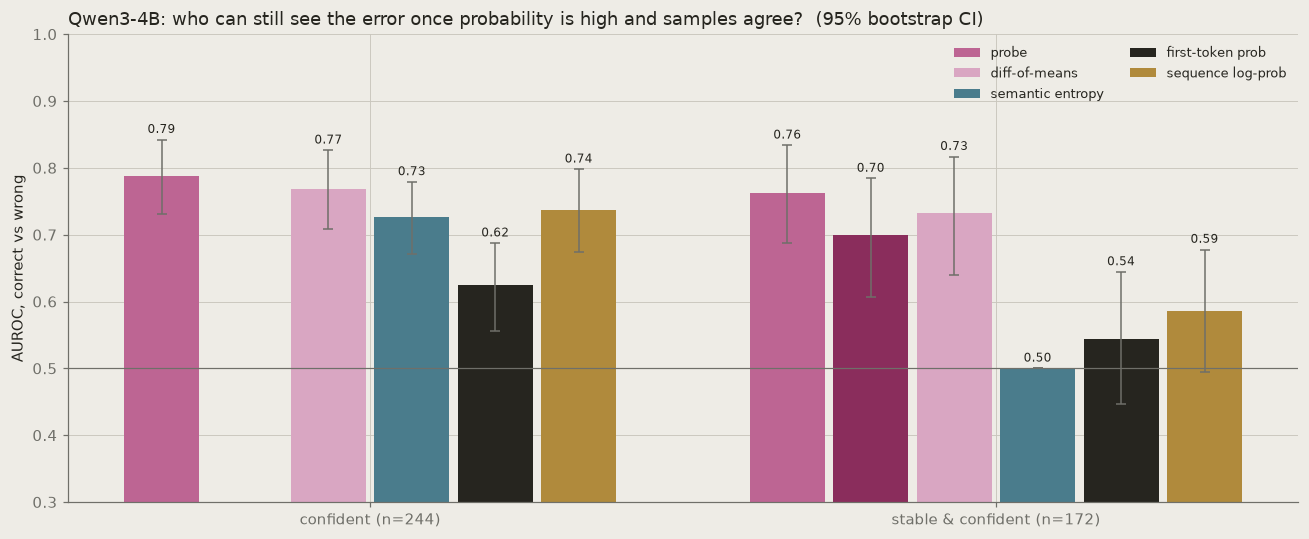

In [24]:
m = "Qwen3-4B"; sub_all = hard_auroc[hard_auroc.model == m]
subsets = list(dict.fromkeys(sub_all.subset)); scores = ["probe", "probe trained within hard set", "diff-of-means", "semantic entropy", "first-token prob", "sequence log-prob"]
cols = {"probe": ACCENT, "probe trained within hard set": "#8a2d5c", "diff-of-means": "#d9a6c2", "semantic entropy": "#4a7c8c", "first-token prob": INK, "sequence log-prob": "#b08a3c"}
fig, ax = plt.subplots(figsize=(12, 5)); w = 0.8 / len(scores)
for i, sc in enumerate(scores):
    for j, ss in enumerate(subsets):
        r = sub_all[(sub_all.subset == ss) & (sub_all.score == sc)]
        if r.empty: continue
        r = r.iloc[0]; x = j + (i - (len(scores) - 1) / 2) * w
        ax.bar(x, r.AUROC, w * 0.9, color=cols[sc], yerr=[[r.AUROC - r["CI lo"]], [r["CI hi"] - r.AUROC]], capsize=3, error_kw=dict(ecolor=MUTED, lw=1), label=sc if j == 0 else None)
        ax.text(x, r["CI hi"] + 0.01, f"{r.AUROC:.2f}", ha="center", fontsize=8)
ax.axhline(0.5, color=MUTED, lw=0.8); ax.set_ylim(0.3, 1.0); ax.set_xticks(range(len(subsets))); ax.set_xticklabels(subsets)
ax.set_title(f"{m}: who can still see the error once probability is high and samples agree?  (95% bootstrap CI)"); ax.set_ylabel("AUROC, correct vs wrong"); ax.legend(loc="upper right", fontsize=8.5, ncol=2)
save(fig, "18_hard_set_auroc")

**Read:** the right-hand group is the whole project in one chart. On the 172 answers that are confident *and* stable under sampling, every output-side score collapses: semantic entropy is constant (0.50 by definition), first-token probability 0.54, sequence log-prob 0.59 with a CI that touches chance. The probe holds at 0.76 (CI 0.69 to 0.84). The stricter "probe trained within hard set" never saw an uncertain or unstable answer during training, so it cannot be reading confidence or instability by proxy, and it still reaches 0.70 (CI 0.61 to 0.78). This is the cleanest statement of H1 the data allows: the residual stream carries information about the error on exactly the answers where nothing the model outputs does. The CIs are wide because the set is 172 questions; a 2,000-question sampling run would tighten them.

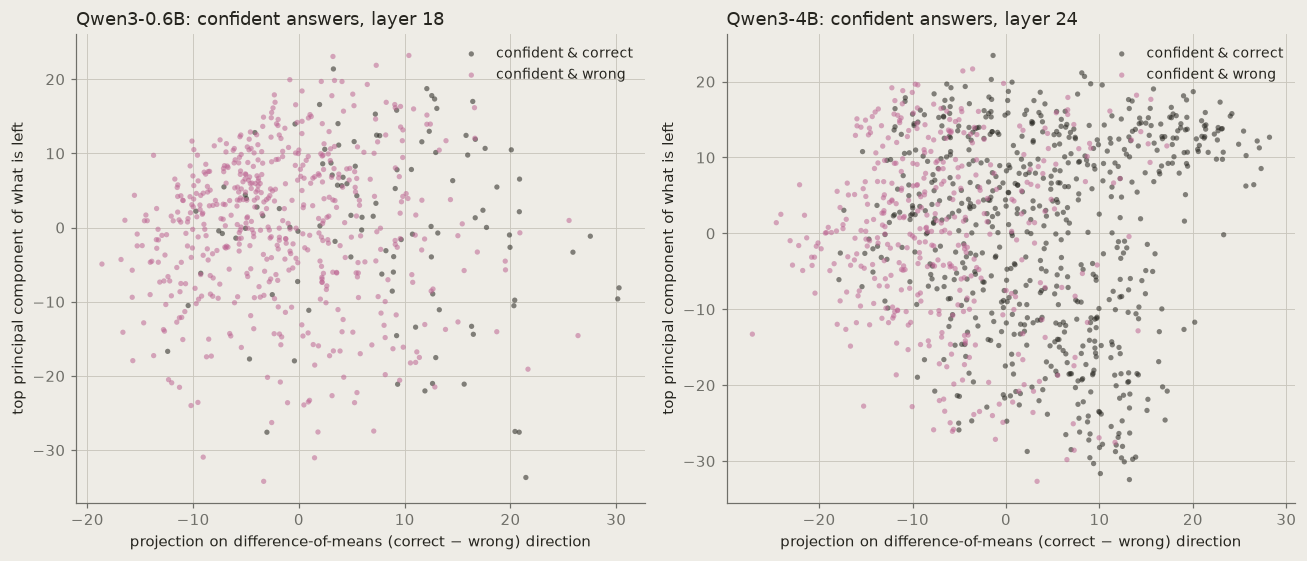

In [25]:
from sklearn.decomposition import PCA
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (m, run) in zip(axes, RUNS.items()):
    d = REC[m]; conf = d.confident.values; pos = "last_prompt"; bl = BEST[m][pos]; acts = load_acts(run, pos)
    if acts is None: ax.text(0.5, 0.5, "activations not available", ha="center", transform=ax.transAxes); continue
    x = StandardScaler().fit_transform(acts[conf][:, bl, :]); y = d.correct.values[conf]
    # supervised 2D: axis 1 = diff-of-means direction, axis 2 = top PC of the residual
    axis = x[y == 1].mean(0) - x[y == 0].mean(0); axis /= np.linalg.norm(axis)
    proj1 = x @ axis; resid = x - np.outer(proj1, axis); proj2 = PCA(1, random_state=0).fit_transform(resid)[:, 0]
    rng = np.random.default_rng(0); order = rng.permutation(len(y))
    for lab, c, name in [(1, C_CORRECT, "confident & correct"), (0, C_WRONG, "confident & wrong")]:
        sel = order[y[order] == lab]; ax.scatter(proj1[sel], proj2[sel], s=12, color=c, alpha=0.55, edgecolors="none", label=name)
    ax.set_title(f"{m}: confident answers, layer {bl}"); ax.set_xlabel("projection on difference-of-means (correct − wrong) direction"); ax.set_ylabel("top principal component of what is left"); ax.legend(fontsize=9)
save(fig, "19_geometry_confident")

**Read:** one picture of the geometry. The horizontal axis is the truth direction from Phase 4; the vertical axis is the largest remaining direction of variation, which the truth direction ignores. The populations separate along the horizontal axis and not the vertical one, which is what a single linear direction looks like. (This is in-sample for the direction, so it is illustrative, not evidence; the out-of-fold AUROCs above are the evidence.)

## Phase 5. Side by side with the papers, and the directional question

**What this computes.** First, a table that puts each paper's headline claim next to the number our setup produces for the same question. Second, the first clean version of the CSO-style directional measurement: the cosine between the correctness direction and the confidence direction in the residual stream, computed so the two labels do not overlap.

**What it mirrors.** CSO-LLM's per-pair displacement cosine (Miller et al.), applied here to population mean-difference axes rather than per-pair displacements. The per-pair version needs CHOKE-style paired prompts and is Nov 6 work.

**Why it matters.** The deck flagged that the earlier cosine was confounded: at 4B confident answers are mostly correct and at 0.6B mostly wrong, so "correct − wrong" and "confident − uncertain" were nearly the same split. Here the correctness axis is estimated only within confident answers and the confidence axis only within correct answers. If the two directions are still nearly parallel, "wrongness" and "low confidence" are one feature and a probe on the confident subset is reading residual confidence. If they are closer to orthogonal, the probe is reading something the model's confidence does not express, which is the premise of the whole project.

In [26]:
def best_row(m, pos="last_prompt"):
    bl = BEST[m][pos]; return LAYERS[(LAYERS.model == m) & (LAYERS.position == pos) & (LAYERS.layer == bl)].iloc[0]
side = []
for m in RUNS:
    d = REC[m]; r = best_row(m); conf = d.confident
    se_row = se_auroc[(se_auroc.model == m) & (se_auroc.score == "semantic entropy (negated)")].iloc[0] if m in SE else None
    side.append({"model": m,
        "token-prob AUROC, all": auroc(d.correct, d.first_tok_prob), "token-prob AUROC, confident": auroc(d.correct[conf], d.first_tok_prob[conf]),
        "semantic entropy AUROC, all (n=500)": se_row["AUROC all"] if se_row is not None else np.nan,
        "semantic entropy AUROC, confident": se_row["AUROC confident"] if se_row is not None else np.nan,
        "probe AUROC, all": r["probe all"], "probe AUROC, confident": r["probe confident"], "best layer": int(r.layer),
        "confident-wrong share of all answers": float((conf & (d.correct == 0)).mean())})
ours = pd.DataFrame(side).set_index("model").T
papers = pd.DataFrame([
    {"paper": "Farquhar et al. 2024 (semantic entropy)", "claim": "SE beats naive entropy and p(True) at predicting confabulations on TriviaQA, across LLaMA-2 / Falcon / Mistral", "our analogue": "semantic entropy AUROC rows", "verify in paper": "Fig. 2 / Supp. tables"},
    {"paper": "Simhi et al. 2025 (CHOKE)", "claim": "A sizeable, stable share of hallucinations are high-certainty, across models and datasets; existing detectors degrade on them", "our analogue": "confident-wrong share; Phase 3 figures", "verify in paper": "Table 1 / Fig. 2"},
    {"paper": "Orgad et al. 2024 (LLMs know more)", "claim": "Probes on exact-answer tokens beat logit-based scores; middle layers best; probes do not transfer across tasks", "our analogue": "probe vs token-prob rows; best layer", "verify in paper": "Table 1 / Fig. 3"},
])
display(ours.round(3)); papers

model,Qwen3-0.6B,Qwen3-4B
"token-prob AUROC, all",0.581,0.814
"token-prob AUROC, confident",0.554,0.678
"semantic entropy AUROC, all (n=500)",0.735,0.831
"semantic entropy AUROC, confident",0.752,0.726
"probe AUROC, all",0.752,0.784
"probe AUROC, confident",0.787,0.764
best layer,18.000,24.000
confident-wrong share of all answers,0.266,0.202


,paper,claim,our analogue,verify in paper
0,Farquhar et al. 2024 (semantic entropy),SE beats naive entropy and p(True) at predicting confabulations on...,semantic entropy AUROC rows,Fig. 2 / Supp. tables
1,Simhi et al. 2025 (CHOKE),"A sizeable, stable share of hallucinations are high-certainty, acr...",confident-wrong share; Phase 3 figures,Table 1 / Fig. 2
2,Orgad et al. 2024 (LLMs know more),Probes on exact-answer tokens beat logit-based scores; middle laye...,probe vs token-prob rows; best layer,Table 1 / Fig. 3


**Read:** the top table is ours, the bottom is theirs in words. The numeric cells of the papers are left for you to fill from the papers' own tables before the tex quotes them. The qualitative pattern lines up: SE above token-based scores, a 20 to 27% confident-wrong population, probes above output scores on the confident subset with a mid-stack best layer. The one place we diverge from the "internal beats output" story is overall AUROC at 4B, where sequence log-prob (0.85) beats the probe (0.79). That is worth saying plainly in the review: the internal signal matters where the output signal is saturated, not everywhere.

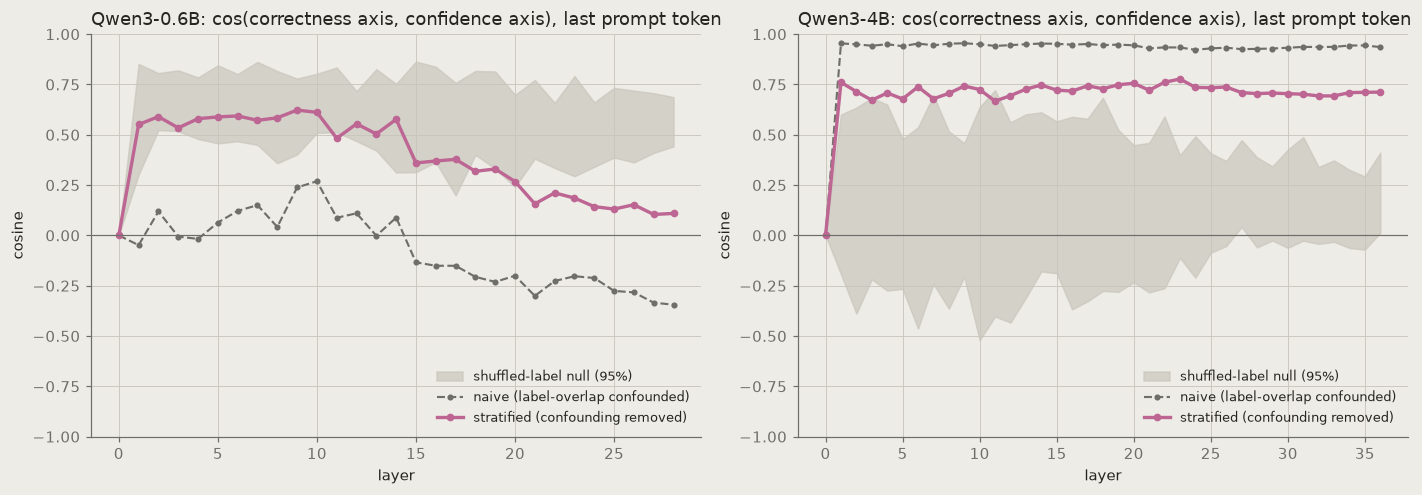

,"naive, mean over layers","stratified, mean over layers",stratified at best probe layer
Qwen3-0.6B,-0.070,0.385,0.319
Qwen3-4B,0.916,0.700,0.736


In [27]:
def unit(v): return v / (np.linalg.norm(v) + 1e-12)
def axis_cosine_stratified(x, y, conf):
    corr_axis = x[conf & (y == 1)].mean(0) - x[conf & (y == 0)].mean(0)       # correctness, within confident only
    conf_axis = x[(y == 1) & conf].mean(0) - x[(y == 1) & ~conf].mean(0)      # confidence, within correct only
    return float(unit(corr_axis) @ unit(conf_axis))
def axis_cosine_naive(x, y, conf):
    return float(unit(x[y == 1].mean(0) - x[y == 0].mean(0)) @ unit(x[conf].mean(0) - x[~conf].mean(0)))

COS = {}
rng = np.random.default_rng(0)
for m, run in RUNS.items():
    d = REC[m]; y = d.correct.values; conf = d.confident.values; acts = load_acts(run, "last_prompt")
    if acts is None: continue
    L = acts.shape[1]; naive, strat, null_lo, null_hi = [], [], [], []
    for l in range(L):
        x = acts[:, l, :]; x = (x - x.mean(0)) / (x.std(0) + 1e-6)
        naive.append(axis_cosine_naive(x, y, conf)); strat.append(axis_cosine_stratified(x, y, conf))
        nulls = [axis_cosine_stratified(x, rng.permutation(y), conf) for _ in range(20)]
        null_lo.append(np.percentile(nulls, 2.5)); null_hi.append(np.percentile(nulls, 97.5))
    COS[m] = pd.DataFrame({"layer": range(L), "naive": naive, "stratified": strat, "null lo": null_lo, "null hi": null_hi})

fig, axes = plt.subplots(1, len(COS), figsize=(6.5 * len(COS), 4.6), squeeze=False); axes = axes[0]
for ax, (m, c) in zip(axes, COS.items()):
    ax.fill_between(c.layer, c["null lo"], c["null hi"], color=RULE, alpha=0.7, label="shuffled-label null (95%)")
    ax.plot(c.layer, c.naive, color=MUTED, lw=1.4, ls="--", marker="o", ms=3, label="naive (label-overlap confounded)")
    ax.plot(c.layer, c.stratified, color=ACCENT, lw=2.2, marker="o", ms=4, label="stratified (confounding removed)")
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_ylim(-1, 1)
    ax.set_title(f"{m}: cos(correctness axis, confidence axis), last prompt token"); ax.set_xlabel("layer"); ax.set_ylabel("cosine"); ax.legend(fontsize=8.5, loc="lower right")
save(fig, "20_axis_cosine_stratified")
pd.DataFrame({m: {"naive, mean over layers": c.naive.mean(), "stratified, mean over layers": c.stratified.mean(), "stratified at best probe layer": c.stratified[BEST[m]["last_prompt"]]} for m, c in COS.items()}).T.round(3)

**Read:** the grey dashed line is the number the deck flagged as confounded: near +1 at 4B and negative at 0.6B, tracking label overlap rather than geometry. The pink line is the same question asked properly, and the grey band is what it looks like when correctness labels are shuffled.

Two things to take from this. First, a methodological one for the CSO-style measurement: the shuffled null is *not* centred on zero. Mean-difference vectors in the residual stream live mostly in a few dominant directions, so two unrelated axes have a cosine of 0.3 to 0.7 by accident. Any cosine criterion needs a null like this, or whitening, before "high cosine" means anything. Second, the two models disagree. At 0.6B the stratified cosine falls *below* the null in the later layers (0.1 to 0.3 against a band of 0.4 to 0.7): the correctness direction is specifically off the confidence subspace. At 4B it sits at the top edge of or above the null (about 0.7): correctness and confidence are substantially one feature there. The next figure checks the same thing with out-of-fold prediction instead of geometry.

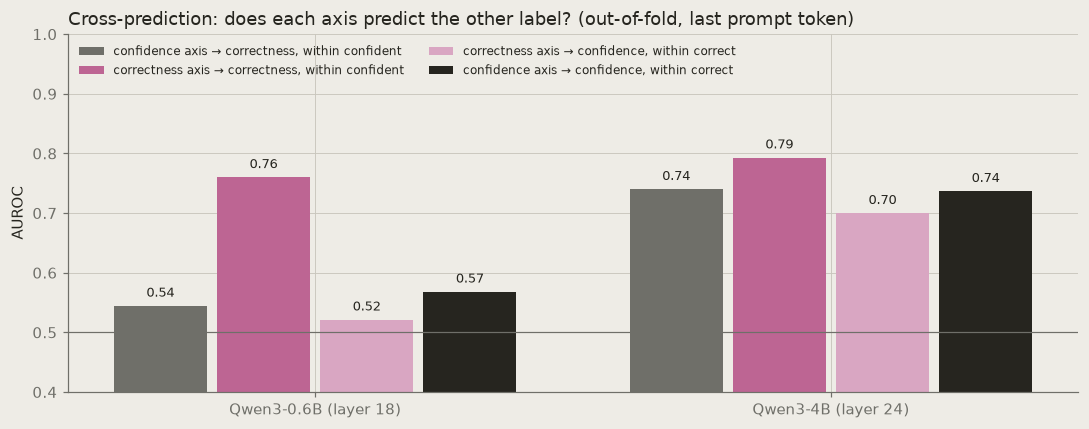

,layer,"confidence axis → correctness, within confident","correctness axis → correctness, within confident","correctness axis → confidence, within correct","confidence axis → confidence, within correct"
model,,,,,
Qwen3-0.6B,18,0.545,0.760,0.521,0.568
Qwen3-4B,24,0.740,0.793,0.700,0.737


In [28]:
# Does the confidence direction itself predict correctness within the confident subset? (if yes, the probe may be reading residual confidence)
rows = []
for m, run in RUNS.items():
    d = REC[m]; y = d.correct.values; conf = d.confident.values; acts = load_acts(run, "last_prompt")
    if acts is None: continue
    bl = BEST[m]["last_prompt"]; x = acts[:, bl, :]; x = (x - x.mean(0)) / (x.std(0) + 1e-6)
    sc_conf, sc_corr = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(x, y * 2 + conf):
        conf_axis = x[tr][(y[tr] == 1) & conf[tr]].mean(0) - x[tr][(y[tr] == 1) & ~conf[tr]].mean(0)
        corr_axis = x[tr][conf[tr] & (y[tr] == 1)].mean(0) - x[tr][conf[tr] & (y[tr] == 0)].mean(0)
        sc_conf[te] = x[te] @ unit(conf_axis); sc_corr[te] = x[te] @ unit(corr_axis)
    rows.append({"model": m, "layer": bl,
                 "confidence axis → correctness, within confident": auroc(y[conf], sc_conf[conf]),
                 "correctness axis → correctness, within confident": auroc(y[conf], sc_corr[conf]),
                 "correctness axis → confidence, within correct": auroc(conf[y == 1].astype(int), sc_corr[y == 1]),
                 "confidence axis → confidence, within correct": auroc(conf[y == 1].astype(int), sc_conf[y == 1])})
cross = pd.DataFrame(rows).set_index("model")
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(cross)); w = 0.2; keys = [c for c in cross.columns if c != "layer"]; cols = [MUTED, ACCENT, "#d9a6c2", INK]
for i, (k, c) in enumerate(zip(keys, cols)):
    b = ax.bar(x + (i - 1.5) * w, cross[k], w * 0.9, color=c, label=k); label_bars(ax, b, dy=0.01)
ax.axhline(0.5, color=MUTED, lw=0.8); ax.set_ylim(0.4, 1.0); ax.set_xticks(x); ax.set_xticklabels([f"{m} (layer {int(cross.loc[m, 'layer'])})" for m in cross.index])
ax.set_title("Cross-prediction: does each axis predict the other label? (out-of-fold, last prompt token)"); ax.set_ylabel("AUROC"); ax.legend(fontsize=8, loc="upper left", ncol=2)
save(fig, "21_axis_cross_prediction")
cross.round(3)

**Read:** the pink bar is the correctness direction doing its own job inside the confident subset; the grey bar is the confidence direction trying to do that same job. At 0.6B they come apart cleanly: 0.76 against 0.54. Wrongness has its own direction in that model, and it is not the direction that encodes how sure the model is. At 4B they largely coincide: 0.74 against 0.79, and the mirror test says the same (0.70 against 0.74). In the larger model the internal correctness signal is mostly an internal *confidence* signal, one the model carries but does not express in its output probability or its samples. That is still a monitor the output cannot provide, as the hard-set result shows, but it is a different claim from "a separate wrongness direction," and the review should say which one each model supports. The per-pair displacement cosine that CSO-LLM actually uses needs paired prompts and is the Nov 6 experiment.

### Where the notebook leaves the argument

1. Output probability knows on average and goes quiet on confident answers (Phase 1).
2. Semantic entropy recovers the unstable half of confident errors and is blind by construction to the stable half (Phase 2).
3. That stable, confident, wrong population is 20 to 27% of questions and does not go away with threshold or scale (Phase 3).
4. A linear probe on the residual stream separates confident-correct from confident-wrong. On the confident subset it beats first-token probability on both models (H1 as pre-registered), ties sequence log-prob at 4B, and on the stable hard set it is the only signal left standing: 0.76 against 0.50 to 0.59 for everything output-side (Phase 4).
5. With label overlap removed, the correctness and confidence directions are distinct at 0.6B and largely shared at 4B. The residual-stream cosine has a non-zero null from anisotropy, which any CSO-style criterion must account for (Phase 5; first look at H2).

Not yet done: LLM-judge label audit, TriviaQA to NQ transfer, and CHOKE-style paired perturbations for the per-pair cosine.